# JATS4R Compliance Analysis - Data Availability Statements (2011-2025)

## What is JATS4R?

**JATS for Reuse (JATS4R)** is a NISO community working group that publishes
prescriptive best-practice recommendations for tagging scholarly articles in
JATS XML. Where the core JATS standard is intentionally permissive, JATS4R
narrows the choices to promote machine-readability and downstream reuse.
Member organisations include Elsevier, SpringerNature, eLife, PLoS, MIT Press,
OUP, Cambridge UP, Wiley, BMJ, Crossref, NCBI, and EMBL-EBI.

---

## The DAS recommendation (published 28 December 2018)

Six normative rules, each with a defined validator outcome:

| Rule | Requirement | Validator on failure |
|------|-------------|----------------------|
| **R1** | DAS `<sec>` must live inside `<back>` | ERROR |
| **R2** | `sec-type="data-availability"` - exact value, lowercase, hyphenated, no suffix | ERROR |
| **R3** | `<title>Data Availability</title>` - exact text | ERROR |
| **R4** | Four valid locations for data citations within or alongside the DAS | - |
| **R5** | `@publication-type="data"` on every `<element-citation>` / `<mixed-citation>` that points to a dataset | ERROR |
| **R6** | Optional `@specific-use`: `generated`, `analyzed`, `supporting`, `non-analyzed` | WARNING on non-standard values |

**Rule 2 explicitly names 16 wrong-value variants as validator ERRORs**, including:
`"Data Availability"`, `"Data-Availability"`, `"data-availability-statement"`,
`"Data_Availability"`, `"Data Accessibility"` and 11 others.

---

## How the corpus captures compliance

`data_availability.source` records the **exact XML path** the ingest pipeline
used to locate the DAS in each PMC article's JATS XML. Because the pipeline
writes the publisher's own attribute value verbatim into this field, it gives
us **ground-truth, per-article compliance data** - not a survey or sample.

| `source` value | JATS4R status | Notes |
|----------------|---------------|-------|
| `sec[@sec-type='data-availability']` | ✅ **Compliant** | Exact R2 value |
| `sec[@sec-type='Data Availability']` | ❌ Near-miss | R2 ERROR - wrong case |
| `sec[@sec-type='<any other value>']` | ❌ Near-miss | R2 ERROR |
| `data-availability element` | ❌ Near-miss | Legacy `<data-availability>` element; JATS4R proposed this element in Apr 2017 - JATS Standing Committee denied it Nov 2017 |
| `sec/title='Data Availability'` | ⚠️ Title-only | No `sec-type` at all; R3 title is correct |
| `sec/title='<other title>'` | ⚠️ Title-only | R2 and R3 both non-compliant |
| `custom-meta/<name>` | ❌ Non-standard | Publisher metadata field |
| `notes[@notes-type='...']` | ❌ Non-standard | Notes element |
| `fn-group/fn` | ❌ Non-standard | Buried in footnote |
| *(empty)* | - | No DAS found |

---

## Sections

| § | Content |
|---|---------|
| 0 | Setup, compliance engine, master frame |
| 1 | Corpus-level compliance distribution |
| 2 | `sec-type` value zoo - what publishers actually write |
| 3 | Section title zoo - heading text variants |
| 4 | Adoption over time: pre/post JATS4R recommendation |
| 5 | data-sharing score by compliance tier |
| 6 | DAS quality signals by compliance tier |
| 7 | DAS verbosity and keyword content by compliance tier |
| 8 | Publisher compliance league table |
| 9 | Compliance by OA tier |
| 10 | Compliance by discipline *(Stage 6)* |
| 11 | Compliance by funder *(Stage 6)* |
| 12 | Four-period analysis |
| 13 | DAS link types and data-citation structure |
| 14 | Statistical summary + exports |


In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


---
## §0 - Setup & Compliance Engine

In [2]:
import sqlite3, warnings, importlib, re
import matplotlib; importlib.reload(matplotlib)
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings('ignore')
importlib.reload(matplotlib); plt = matplotlib.pyplot
sns.set_theme(style='whitegrid', font_scale=1.15)

FAIR_YEAR = 2016
FIG_W, FIG_H = 13, 5

# Compliance-tier colours and labels
C_PAL = {
    'compliant':    '#2ca02c',
    'near_miss':    '#ff7f0e',
    'title_only':   '#1f77b4',
    'non_standard': '#9467bd',
    'no_das':       '#d3d3d3',
}
C_LABEL = {
    'compliant':    'Compliant  (sec-type="data-availability")',
    'near_miss':    'Near-miss  (wrong sec-type or legacy element)',
    'title_only':   'Title-only (found by heading; no sec-type)',
    'non_standard': 'Non-standard (custom-meta / notes / fn)',
    'no_das':       'No DAS found',
}
C_ORDER = ['compliant', 'near_miss', 'title_only', 'non_standard', 'no_das']

DB_PATH = Path('../data/processed/pmc_fair.db')
assert DB_PATH.exists(), f'Database not found: {DB_PATH}'

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")
con = sqlite3.connect(DB_PATH)
con.row_factory = sqlite3.Row

def qdb(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

tables = {r[0] for r in con.execute(
    "SELECT name FROM sqlite_master WHERE type='table'").fetchall()}
HAS_DISC   = 'article_discipline' in tables
HAS_FUNDER = 'article_funder'     in tables
HAS_OA     = 'journal_oa'         in tables

print(f"Discipline  (Stage 6): {chr(9989) if HAS_DISC   else chr(9888)}")
print(f"Funder      (Stage 6): {chr(9989) if HAS_FUNDER else chr(9888)}")
print(f"OA status   (Stage 6): {chr(9989) if HAS_OA     else chr(9888)}")

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


Discipline  (Stage 6): ✅
Funder      (Stage 6): ✅
OA status   (Stage 6): ✅


### Compliance classifier

The classifier maps `data_availability.source` strings (written verbatim by the pipeline from the JATS XML) to one of four compliance tiers plus `no_das`.

In [3]:
# ── Source-string patterns ───────────────────────────────────────────────────
# The pipeline writes source strings in these forms (from pubmed_to_sqlite.py):
#   "sec[@sec-type='<VALUE>']"   ← sec-type attribute found, VALUE is verbatim
#   "sec/title='<TITLE>'"        ← found only by heading text; no sec-type
#   "data-availability element"  ← legacy <data-availability> element
#   "custom-meta/<name>"         ← custom metadata field
#   "notes[@notes-type='<V>']"   ← notes element
#   "fn-group/fn"                ← footnote
#   ""                           ← no DAS at all

_SECTYPE_RE  = re.compile(r"^sec\[@sec-type='(.+)'\]$")
_TITLE_RE    = re.compile(r"^sec/title='(.+)'$")
_NOTES_RE    = re.compile(r"^notes\[@notes-type='.*'\]$")
_CMETA_RE    = re.compile(r"^custom-meta/")

# The ONE exact value JATS4R Rule 2 requires
JATS4R_EXACT_SOURCE = "sec[@sec-type='data-availability']"

# The 16 wrong-value variants JATS4R explicitly names as validator ERRORs
JATS4R_ERROR_VALUES = {
    'Data availability', 'Data Availability', 'Data-Availability',
    'data availability statement', 'Data availability statement',
    'Data Availability Statement', 'data-availability-statement',
    'Data-availability-statement', 'Data-Availability-Statement',
    'Data_Availability', 'data_availability-statement',
    'Data_availability-statement', 'Data_Availability-Statement',
    'data_availability', 'Data Accessibility', 'data accessibility',
}

def classify(source):
    s = str(source or '').strip()
    if not s:
        return 'no_das'
    if s == JATS4R_EXACT_SOURCE:
        return 'compliant'
    if _SECTYPE_RE.match(s):           # any sec-type other than exact value
        return 'near_miss'
    if s == 'data-availability element':  # legacy element (JATS4R denied Nov 2017)
        return 'near_miss'
    if _TITLE_RE.match(s):
        return 'title_only'
    if _CMETA_RE.match(s) or _NOTES_RE.match(s) or s == 'fn-group/fn':
        return 'non_standard'
    return 'non_standard'

def sectype_val(source):
    m = _SECTYPE_RE.match(str(source or ''))
    return m.group(1) if m else None

def title_val(source):
    m = _TITLE_RE.match(str(source or ''))
    return m.group(1) if m else None

# Quick self-test
assert classify(JATS4R_EXACT_SOURCE)             == 'compliant'
assert classify("sec[@sec-type='Data Availability']") == 'near_miss'
assert classify("data-availability element")     == 'near_miss'
assert classify("sec/title='Data Availability'") == 'title_only'
assert classify("custom-meta/data availability") == 'non_standard'
assert classify("")                              == 'no_das'
print("Compliance classifier self-tests passed.")
print(f"  Exact compliant source : {JATS4R_EXACT_SOURCE!r}")
print(f"  Named error variants   : {len(JATS4R_ERROR_VALUES)}")


Compliance classifier self-tests passed.
  Exact compliant source : "sec[@sec-type='data-availability']"
  Named error variants   : 16


### Build master frame

In [4]:
df = qdb("""
    SELECT
        a.article_id,
        a.year    AS year,
        a.journal_id,
        COALESCE(da.source, '')    AS source,
        COALESCE(da.statement, '') AS das_text,
        dc.data_sharing_score,
        dc.primary_category        AS cat,
        dc.mentions_license,
        dc.mentions_doi,
        dc.mentions_github,
        dc.has_url,
        dc.has_accession,
        dc.word_count,
        dc.sentence_count
    FROM article             a
    JOIN das_category        dc ON dc.article_id = a.article_id
    LEFT JOIN data_availability da ON da.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

df['compliance']   = df['source'].apply(classify)
df['is_compliant'] = df['compliance'] == 'compliant'
df['has_das']      = df['source'].str.strip().ne('')
df['sec_type_val'] = df['source'].apply(sectype_val)
df['title_val']    = df['source'].apply(title_val)

# Four-period label
df['period'] = df['year'].apply(
    lambda y: 'pre_fair'      if y < 2016
         else 'fair_yr'       if y == 2016
         else 'post_fair_pre' if y <= 2018
         else 'post_rec')

jrnl = qdb("SELECT journal_id, title AS jrnl_title, publisher, issn_epub, issn_ppub FROM journal")
df   = df.merge(jrnl, on='journal_id', how='left')

print(f"Master frame: {len(df):,} articles × {len(df.columns)} columns")
print()
vc = df['compliance'].value_counts().reindex(C_ORDER).fillna(0).astype(int)
for k in C_ORDER:
    print(f"  {C_LABEL[k]:55}  {vc[k]:>9,}  ({vc[k]/len(df)*100:5.1f}%)")


Master frame: 6,874,176 articles × 24 columns



  Compliant  (sec-type="data-availability")                1,084,305  ( 15.8%)
  Near-miss  (wrong sec-type or legacy element)                  177  (  0.0%)
  Title-only (found by heading; no sec-type)                 189,133  (  2.8%)
  Non-standard (custom-meta / notes / fn)                  1,737,428  ( 25.3%)
  No DAS found                                             3,863,133  ( 56.2%)


---
## §1 - Corpus-Level Compliance Distribution

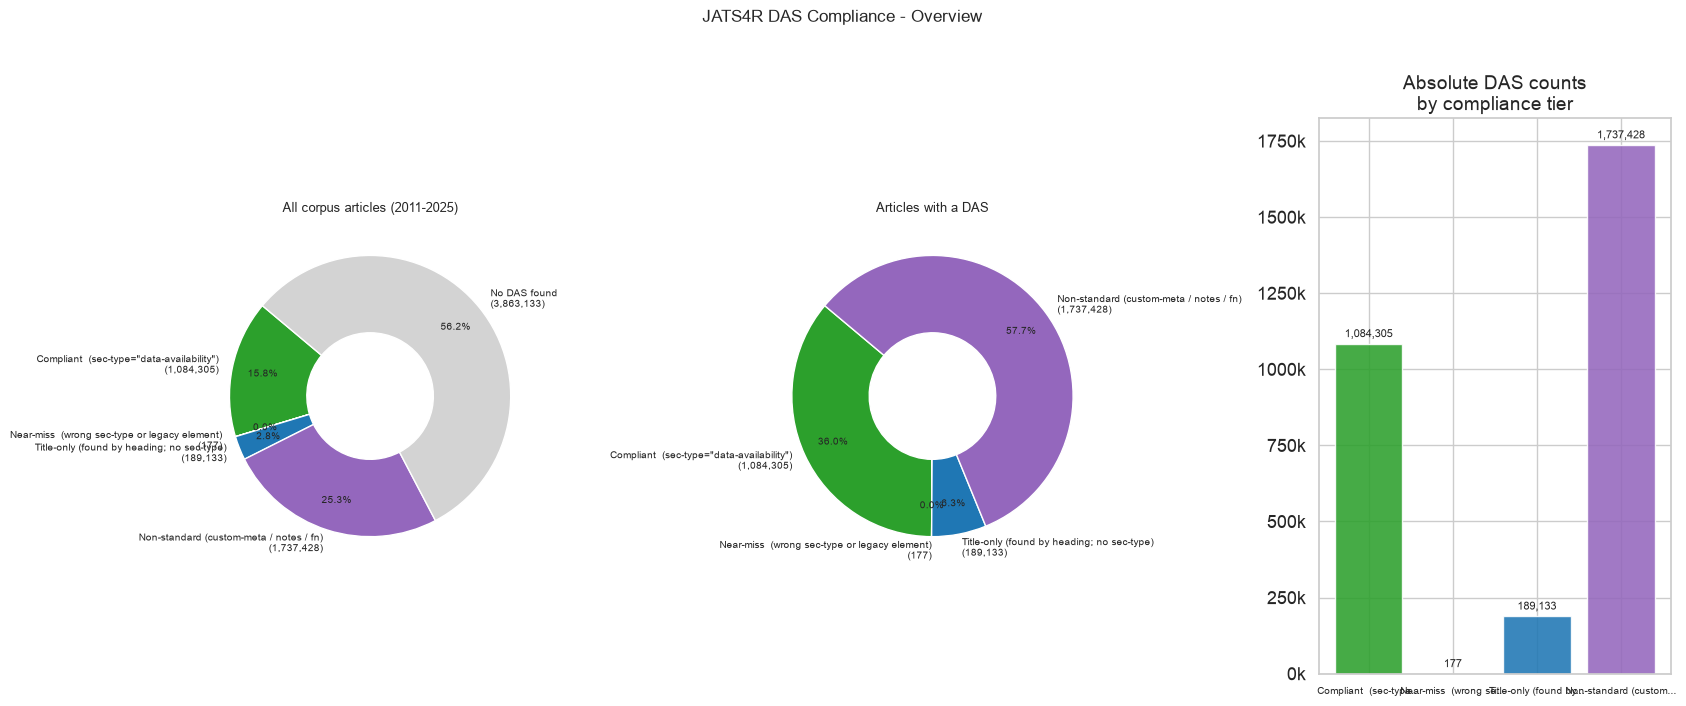

DAS presence rate  : 43.8%  (3,011,043/6,874,176)
JATS4R compliant   : 36.0% of DAS articles  (1,084,305)


In [5]:
tier_all = df['compliance'].value_counts().reindex(C_ORDER).fillna(0)
tier_das = (df[df['has_das']]['compliance']
            .value_counts().reindex(C_ORDER).fillna(0))

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 4, FIG_H + 2))

def donut(ax, data, title, exclude=None):
    keys = [(k, int(data[k])) for k in C_ORDER
            if data[k] > 0 and k != (exclude or '')]
    ax.pie([n for _, n in keys],
           labels=[f'{C_LABEL[k]}\n({n:,})' for k, n in keys],
           colors=[C_PAL[k] for k, _ in keys],
           autopct='%1.1f%%', startangle=140, pctdistance=0.78,
           wedgeprops=dict(width=0.55), textprops={'fontsize': 7})
    ax.set_title(title, fontsize=9)

donut(axes[0], tier_all, 'All corpus articles (2011-2025)')
donut(axes[1], tier_das, 'Articles with a DAS', exclude='no_das')

# Absolute count bar (DAS articles only, by compliance tier)
ax = axes[2]
das_only = [k for k in C_ORDER if k != 'no_das']
bars = ax.bar([C_LABEL[k][:20]+'...' for k in das_only],
              [tier_das[k] for k in das_only],
              color=[C_PAL[k] for k in das_only],
              alpha=0.88, edgecolor='white')
ax.bar_label(bars, fmt='{:,.0f}', padding=3, fontsize=8)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e3:.0f}k'))
ax.set_title('Absolute DAS counts\nby compliance tier')
ax.tick_params(axis='x', labelsize=7)

plt.suptitle('JATS4R DAS Compliance - Overview', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_jats4r_01_overview.png", **SAVEFIG_KWARGS)
plt.show()

n_das = int(df['has_das'].sum())
n_c   = int(df['is_compliant'].sum())
print(f"DAS presence rate  : {n_das/len(df)*100:.1f}%  ({n_das:,}/{len(df):,})")
print(f"JATS4R compliant   : {n_c/n_das*100:.1f}% of DAS articles  ({n_c:,})")


---
## §2 - `sec-type` Value Zoo

Rule 2 is the most precisely specified rule in the JATS4R DAS recommendation:
`sec-type="data-availability"` - lowercase, hyphenated, nothing else.
The validator lists 16 specific wrong values that trigger an ERROR.

This section enumerates every `sec-type` value the corpus actually contains -
a direct audit of whether publishers have updated their XML templates.


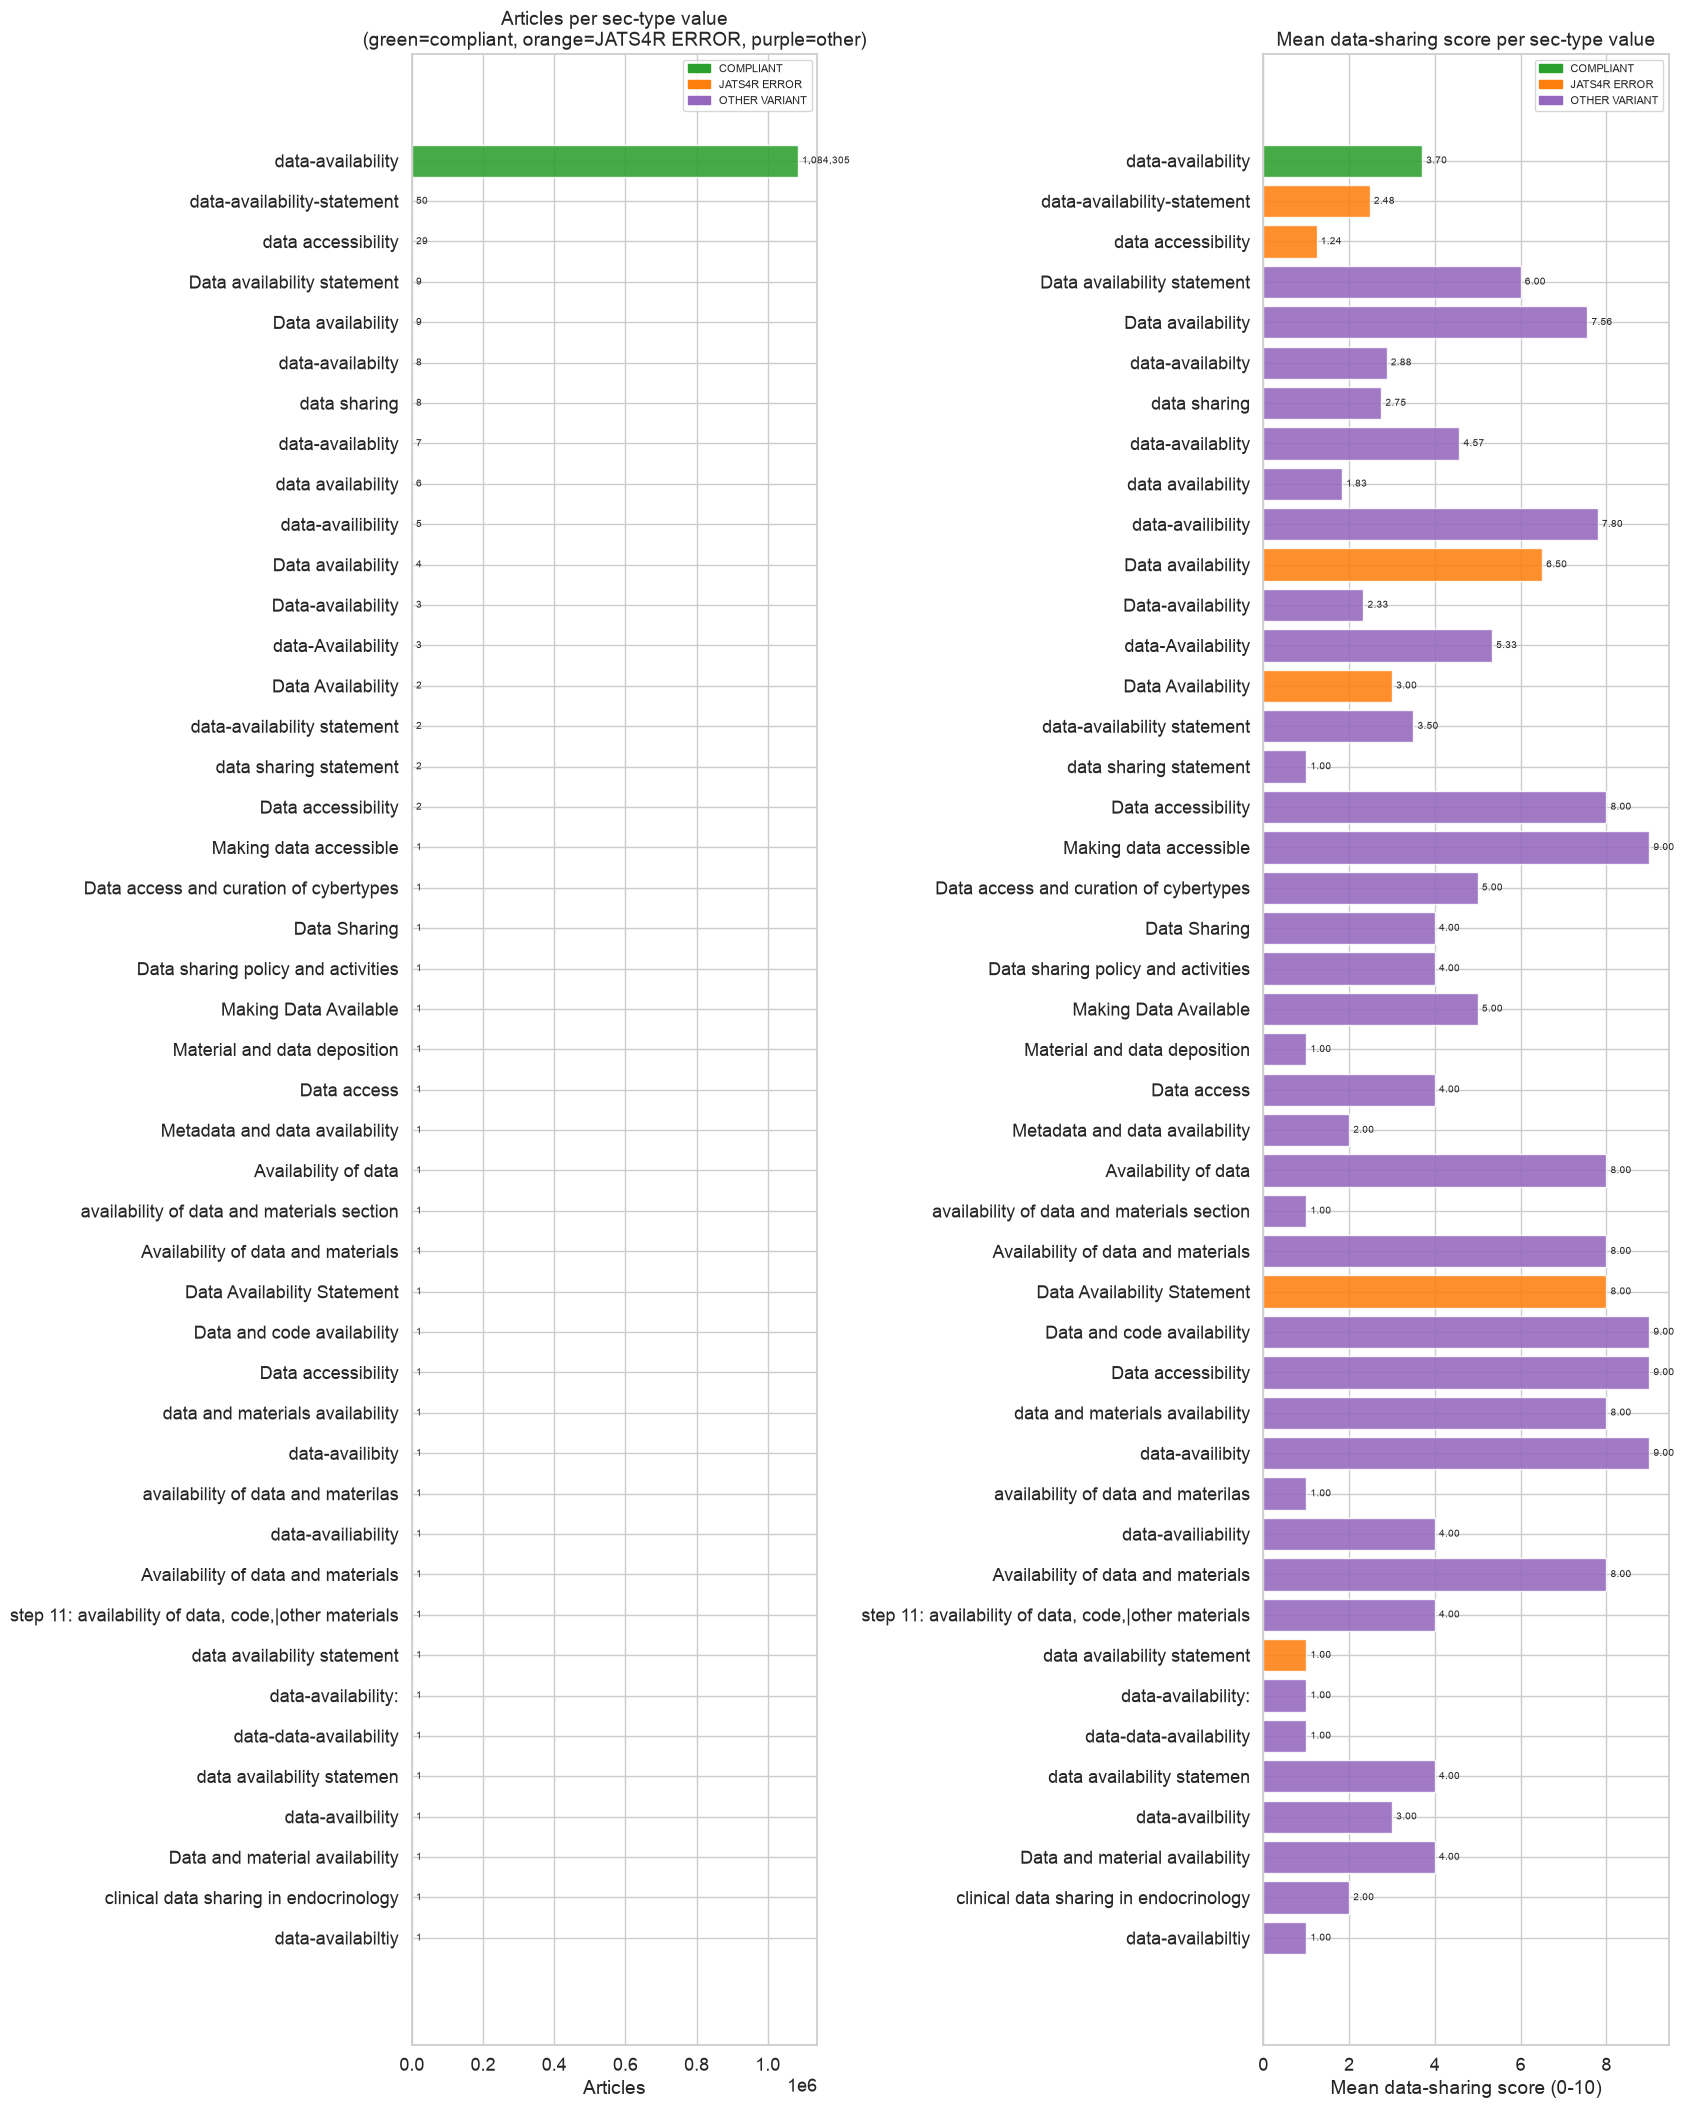

Distinct sec-type values in corpus: 45
  COMPLIANT     : 1 value(s)
  JATS4R ERROR  : 6 value(s)
  OTHER VARIANT : 38 value(s)

                                        sec_type_val       n    pct  mean_score        status
                                   data-availability 1084305 15.774       3.702     COMPLIANT
                         data-availability-statement      50  0.001       2.480  JATS4R ERROR
                                  data accessibility      29  0.000       1.241  JATS4R ERROR
                        ﻿Data availability statement       9  0.000       6.000 OTHER VARIANT
                                  ﻿Data availability       9  0.000       7.556 OTHER VARIANT
                                    data-availabilty       8  0.000       2.875 OTHER VARIANT
                                        data sharing       8  0.000       2.750 OTHER VARIANT
                                    data-availablity       7  0.000       4.571 OTHER VARIANT
                          

In [6]:
st_counts = (
    df[df['sec_type_val'].notna()]
    .groupby('sec_type_val', sort=False)
    .agg(n=('article_id','count'), mean_score=('data_sharing_score','mean'))
    .sort_values('n', ascending=False)
    .reset_index()
)
st_counts['pct']    = st_counts['n'] / len(df) * 100
st_counts['status'] = st_counts['sec_type_val'].apply(
    lambda v: 'COMPLIANT' if v == 'data-availability'
         else 'JATS4R ERROR' if v in JATS4R_ERROR_VALUES
         else 'OTHER VARIANT')

ST_PAL = {'COMPLIANT':'#2ca02c', 'JATS4R ERROR':'#ff7f0e', 'OTHER VARIANT':'#9467bd'}

n_rows = len(st_counts)
fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 4, max(5, n_rows * 0.44 + 1.5)))

for ax, col, xlabel, fmt_fn in [
        (axes[0], 'n',         'Articles', lambda n, _: f'{int(n):,}'),
        (axes[1], 'mean_score', 'Mean data-sharing score (0-10)', lambda v, _: f'{v:.2f}')]:
    clrs = [ST_PAL[s] for s in st_counts['status'][::-1]]
    bars = ax.barh(st_counts['sec_type_val'][::-1],
                   st_counts[col][::-1],
                   color=clrs, alpha=0.88, edgecolor='white')
    ax.bar_label(bars, labels=[fmt_fn(v, None) for v in st_counts[col][::-1]],
                 padding=3, fontsize=7.5)
    ax.set_xlabel(xlabel)
    ax.legend(handles=[mpatches.Patch(color=c, label=l)
                        for l, c in ST_PAL.items()], fontsize=8)

axes[0].set_title('Articles per sec-type value\n'
                  '(green=compliant, orange=JATS4R ERROR, purple=other)')
axes[1].set_title('Mean data-sharing score per sec-type value')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_jats4r_02_sectype_zoo.png", **SAVEFIG_KWARGS)
plt.show()

n_c_vals = (st_counts['status'] == 'COMPLIANT').sum()
n_e_vals = (st_counts['status'] == 'JATS4R ERROR').sum()
n_o_vals = (st_counts['status'] == 'OTHER VARIANT').sum()
print(f"Distinct sec-type values in corpus: {len(st_counts)}")
print(f"  COMPLIANT     : {n_c_vals} value(s)")
print(f"  JATS4R ERROR  : {n_e_vals} value(s)")
print(f"  OTHER VARIANT : {n_o_vals} value(s)")
print()
print(st_counts[['sec_type_val','n','pct','mean_score','status']].round(3).to_string(index=False))


---
## §3 - Section Title Zoo

When the pipeline finds no `sec-type` attribute it falls back to matching on
heading text. Rule 3 requires `<title>Data Availability</title>` exactly.
Here are the actual titles found - each a subtle deviation from the spec.


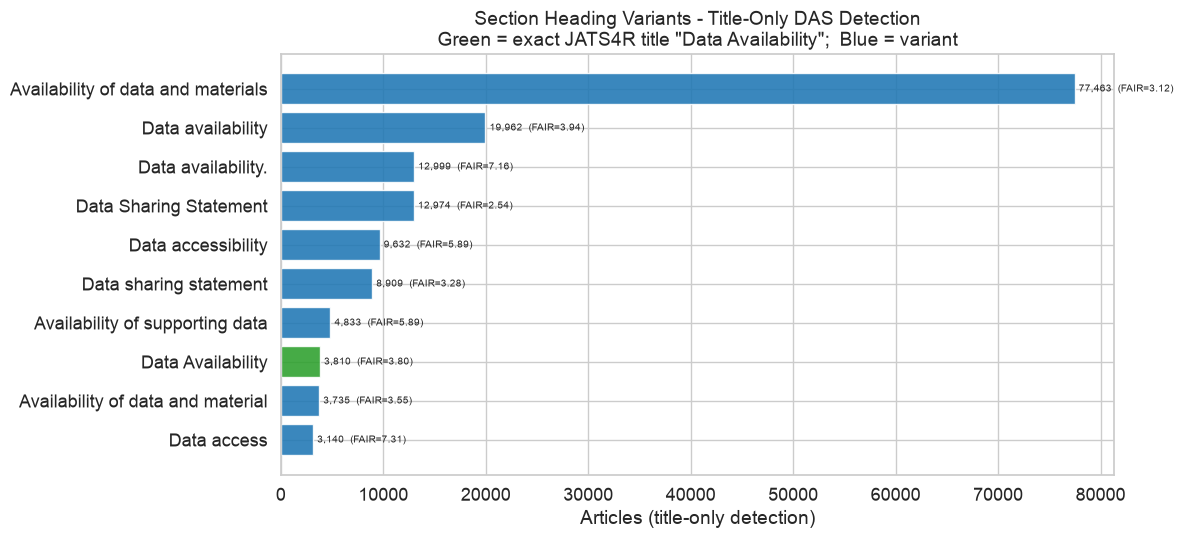

Distinct heading variants: 6982
  Exact 'Data Availability': 1

                         title_val     n  mean_score   pct  r3_exact
Availability of data and materials 77463       3.119 1.127     False
                 Data availability 19962       3.944 0.290     False
                Data availability. 12999       7.162 0.189     False
            Data Sharing Statement 12974       2.535 0.189     False
                Data accessibility  9632       5.889 0.140     False
            Data sharing statement  8909       3.284 0.130     False
   Availability of supporting data  4833       5.894 0.070     False
                 Data Availability  3810       3.801 0.055      True
 Availability of data and material  3735       3.552 0.054     False
                       Data access  3140       7.307 0.046     False


In [7]:
tv_counts = (
    df[df['title_val'].notna()]
    .groupby('title_val', sort=False)
    .agg(n=('article_id','count'), mean_score=('data_sharing_score','mean'))
    .sort_values('n', ascending=False)
    .reset_index()
)
tv_counts['pct']      = tv_counts['n'] / len(df) * 100
tv_counts['r3_exact'] = tv_counts['title_val'] == 'Data Availability'

if len(tv_counts) == 0:
    print("No title-only DAS sections found in this database.")
else:
    top = tv_counts.head(10)
    fig, ax = plt.subplots(figsize=(12, max(5, len(top) * 0.41 + 1.5)))
    clrs = ['#2ca02c' if exact else '#1f77b4'
            for exact in top['r3_exact'][::-1]]
    bars = ax.barh(top['title_val'][::-1], top['n'][::-1],
                   color=clrs, alpha=0.88, edgecolor='white')
    ax.bar_label(bars,
                 labels=[f"{int(n):,}  (FAIR={f:.2f})"
                         for n, f in zip(top['n'][::-1], top['mean_score'][::-1])],
                 padding=3, fontsize=7.5)
    ax.set_xlabel('Articles (title-only detection)')
    ax.set_title('Section Heading Variants - Title-Only DAS Detection\n'
                 'Green = exact JATS4R title "Data Availability";  Blue = variant')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_jats4r_03_title_zoo.png", **SAVEFIG_KWARGS)
    plt.show()

    print(f"Distinct heading variants: {len(tv_counts)}")
    print(f"  Exact 'Data Availability': {tv_counts['r3_exact'].sum()}")
    print()
    print(top.round(3).to_string(index=False))


---
## §4 - Adoption Over Time

Two events define the natural experiment:

- **March 2016** - Wilkinson et al. publish the FAIR principles paper.
- **28 December 2018** - JATS4R DAS recommendation published.
  The first full calendar year in which compliance is even possible is **2019**.

We expect a step-change in compliant tagging from 2019 onwards.
The near-miss rate should fall as publishers replace wrong-case variants
with the authoritative `"data-availability"` string.


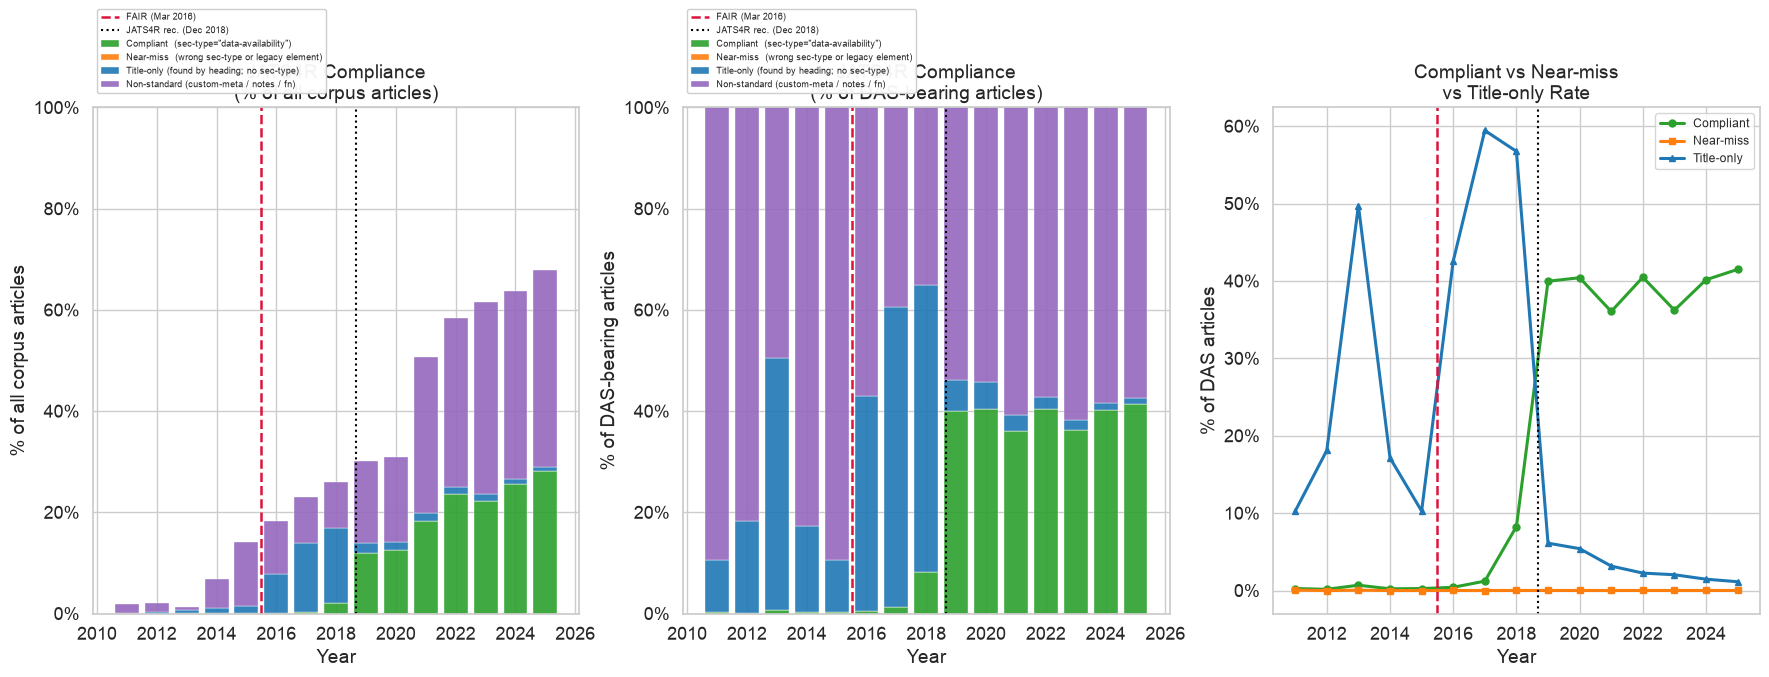

Annual JATS4R compliance rate (% of DAS articles):
  2011:   0.3%
  2012:   0.2%
  2013:   0.7%
  2014:   0.2%
  2015:   0.3%
  2016:   0.4%
  2017:   1.2%
  2018:   8.3%
  2019:  40.0% ← first full post-rec year
  2020:  40.4%
  2021:  36.1%
  2022:  40.5%
  2023:  36.2%
  2024:  40.2%
  2025:  41.5%


In [8]:
yr_tot  = df.groupby('year').size().rename('n_total')
yr_das  = df[df['has_das']].groupby('year').size().rename('n_das')
yr_comp = (df[df['has_das']]
           .groupby(['year','compliance']).size().rename('n')
           .reset_index())
yr_comp = yr_comp.merge(yr_tot, on='year').merge(yr_das, on='year')
yr_comp['pct_corpus'] = yr_comp['n'] / yr_comp['n_total'] * 100
yr_comp['pct_das']    = yr_comp['n'] / yr_comp['n_das']    * 100

piv_corp = (yr_comp.pivot_table(index='year', columns='compliance',
                                 values='pct_corpus', aggfunc='sum').fillna(0))
piv_das  = (yr_comp.pivot_table(index='year', columns='compliance',
                                 values='pct_das',    aggfunc='sum').fillna(0))

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 5, FIG_H + 2))

for ax, piv, sfx in [
        (axes[0], piv_corp, '% of all corpus articles'),
        (axes[1], piv_das,  '% of DAS-bearing articles')]:
    bot = np.zeros(len(piv))
    for t in C_ORDER:
        if t not in piv.columns:
            continue
        ax.bar(piv.index, piv[t].values, bottom=bot,
               color=C_PAL[t], label=C_LABEL[t],
               edgecolor='white', lw=0.3, alpha=0.9, width=0.8)
        bot += piv[t].values
    ax.axvline(2015.5,  color='crimson', lw=1.8, ls='--', label='FAIR (Mar 2016)')
    ax.axvline(2018.67, color='black',   lw=1.5, ls=':',  label='JATS4R rec. (Dec 2018)')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_ylim(0, 100)
    ax.axhline(100, color='grey', lw=0.6, ls=':', zorder=0)
    ax.set_xlabel('Year'); ax.set_ylabel(sfx)
    ax.set_title(f'JATS4R Compliance\n({sfx})')
    ax.legend(fontsize=6.5, loc='lower left', bbox_to_anchor=(0, 1.02), framealpha=0.95)

# Line chart: compliant vs near-miss vs title-only rates over time
ax = axes[2]
for tier, lbl, mrk in [('compliant',  'Compliant',  'o'),
                        ('near_miss',  'Near-miss',  's'),
                        ('title_only', 'Title-only', '^')]:
    if tier in piv_das.columns:
        ax.plot(piv_das.index, piv_das[tier].values,
                lw=2.2, marker=mrk, ms=5, color=C_PAL[tier], label=lbl)
ax.axvline(2015.5,  color='crimson', lw=1.8, ls='--')
ax.axvline(2018.67, color='black',   lw=1.5, ls=':')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Year'); ax.set_ylabel('% of DAS articles')
ax.set_title('Compliant vs Near-miss\nvs Title-only Rate')
ax.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_jats4r_04_over_time.png", **SAVEFIG_KWARGS)
plt.show()

if 'compliant' in piv_das.columns:
    print("Annual JATS4R compliance rate (% of DAS articles):")
    for yr, val in piv_das['compliant'].items():
        tag = ' ← first full post-rec year' if yr == 2019 else ''
        print(f"  {yr}: {val:5.1f}%{tag}")


---
## §5 - Data-Sharing Score by Compliance Tier

**Central research question**: Is JATS4R compliance associated with better
data-sharing practice, or is it purely a back-end XML production choice?

Three hypotheses:
1. **Sophistication coupling** - publishers with mature XML pipelines also
   enforce stronger data policies → compliant articles score higher.
2. **Decoupling** - tagging quality and data-sharing culture are independent.
3. **Inversion** - some subscription publishers are compliant but restrictive
   ("available on request"); some OA journals share openly but haven't yet
   updated their `sec-type` template.


In [9]:
tiers_4 = [t for t in C_ORDER if t != 'no_das']
sc_by_t = {t: df[df['compliance'] == t]['data_sharing_score'].dropna() for t in tiers_4}

stat_rows = []
for t in tiers_4:
    sc = sc_by_t[t]
    if len(sc) < 2:
        continue
    stat_rows.append(dict(
        tier=t, n=len(sc),
        mean=round(sc.mean(),4), median=round(sc.median(),4), std=round(sc.std(),4)))
df_st = pd.DataFrame(stat_rows)
df_st['ci95'] = 1.96 * df_st['std'] / np.sqrt(df_st['n'])

print("data-sharing score by compliance tier:")
print(df_st[['tier','n','mean','median','std','ci95']].round(4).to_string(index=False))
print()
comp_sc = sc_by_t.get('compliant', pd.Series(dtype=float))
print("Mann-Whitney U: compliant vs each other tier")
mw_export = []
for t in ['near_miss','title_only','non_standard']:
    sc = sc_by_t.get(t, pd.Series(dtype=float))
    if len(comp_sc) < 2 or len(sc) < 2:
        continue
    u, p = stats.mannwhitneyu(comp_sc, sc, alternative='two-sided')
    r_e  = u / (len(comp_sc) * len(sc))
    sig  = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
    mw_export.append({'vs': t, 'A_mean': round(comp_sc.mean(),3),
                      'B_mean': round(sc.mean(),3),
                      'delta': round(comp_sc.mean()-sc.mean(),3),
                      'p': f'{p:.2e}', 'r': round(r_e,4), 'sig': sig})
    print(f"  vs {C_LABEL[t][:38]:40}  delta={comp_sc.mean()-sc.mean():+.3f}"
          f"  p={p:.2e}  r={r_e:.4f}  {sig}")
df_mw = pd.DataFrame(mw_export)


data-sharing score by compliance tier:
        tier       n   mean  median    std   ci95
   compliant 1084305 3.7018     3.0 2.4300 0.0046
   near_miss     177 3.4859     3.0 2.7984 0.4123
  title_only  189133 4.0062     4.0 2.7128 0.0122
non_standard 1737428 3.4756     4.0 2.2473 0.0033

Mann-Whitney U: compliant vs each other tier
  vs Near-miss  (wrong sec-type or legacy e    delta=+0.216  p=2.61e-02  r=0.5471  *


  vs Title-only (found by heading; no sec-t    delta=-0.304  p=1.07e-275  r=0.4751  ***


  vs Non-standard (custom-meta / notes / fn    delta=+0.226  p=0.00e+00  r=0.5158  ***


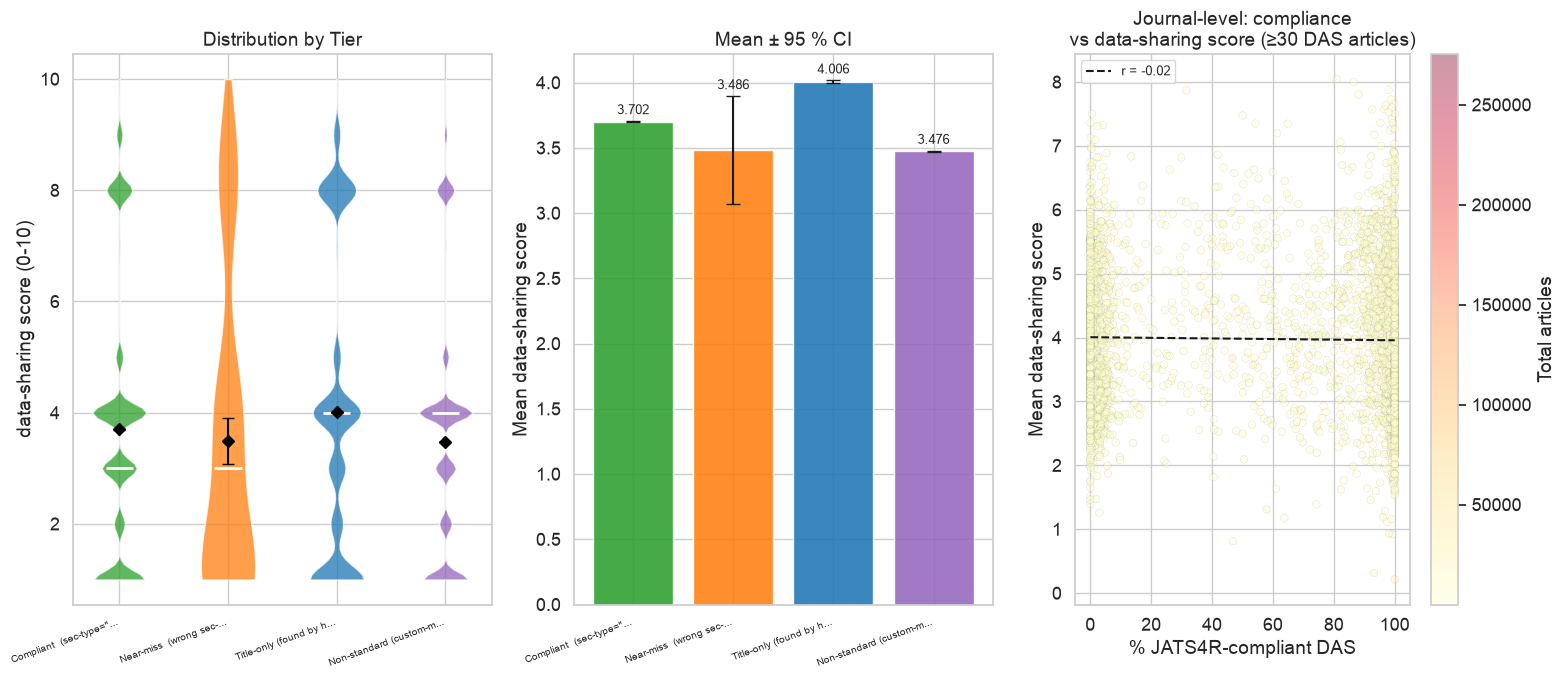

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 3, FIG_H + 2))

# Violin (safe - filter empty groups)
ax = axes[0]
valid = [(i, t) for i, t in enumerate(tiers_4)
         if t in sc_by_t and len(sc_by_t[t]) >= 2]
if valid:
    vidx, vtiers = zip(*valid)
    parts = ax.violinplot([sc_by_t[t].values for t in vtiers],
                          positions=list(vidx),
                          showmedians=True, showextrema=False)
    for pc, t in zip(parts['bodies'], vtiers):
        pc.set_facecolor(C_PAL[t]); pc.set_alpha(0.75)
    parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
for _, row in df_st.iterrows():
    j = tiers_4.index(row['tier']) if row['tier'] in tiers_4 else None
    if j is not None:
        ax.errorbar(j, row['mean'], yerr=row['ci95'],
                    fmt='D', color='black', ms=6, capsize=4, zorder=5)
ax.set_xticks(range(len(tiers_4)))
ax.set_xticklabels([C_LABEL[t][:22]+'...' for t in tiers_4],
                   rotation=20, ha='right', fontsize=7)
ax.set_ylabel('data-sharing score (0-10)')
ax.set_title('Distribution by Tier')

# Mean ± CI bar
ax = axes[1]
x_t = np.arange(len(df_st))
bars = ax.bar(x_t, df_st['mean'],
              color=[C_PAL[t] for t in df_st['tier']],
              alpha=0.88, edgecolor='white',
              yerr=df_st['ci95'], capsize=5)
ax.bar_label(bars, fmt='{:.3f}', padding=3, fontsize=9)
ax.set_xticks(x_t)
ax.set_xticklabels([C_LABEL[t][:22]+'...' for t in df_st['tier']],
                   rotation=20, ha='right', fontsize=7)
ax.set_ylabel('Mean data-sharing score'); ax.set_title('Mean ± 95 % CI')

# Journal-level scatter: compliance % vs mean data-sharing score
ax = axes[2]
j_agg = (df.groupby('journal_id').agg(
    n_total=('article_id','count'),
    n_das=('has_das','sum'),
    n_comp=('is_compliant','sum'),
    mean_score=('data_sharing_score','mean')).reset_index())
j_agg['pct_c'] = j_agg['n_comp'] / j_agg['n_das'].clip(1) * 100
j50 = j_agg[j_agg['n_das'] >= 30]
sc_plot = ax.scatter(j50['pct_c'], j50['mean_score'],
                     alpha=0.4, s=30, c=j50['n_total'],
                     cmap='YlOrRd', edgecolors='grey', lw=0.2)
if len(j50) > 5:
    sl, ic, r, _, _ = stats.linregress(
        j50['pct_c'].fillna(0), j50['mean_score'].fillna(0))
    xs = np.linspace(0, 100, 50)
    ax.plot(xs, ic + sl*xs, 'k--', lw=1.5, label=f'r = {r:.2f}')
    ax.legend(fontsize=9)
plt.colorbar(sc_plot, ax=ax, label='Total articles')
ax.set_xlabel('% JATS4R-compliant DAS')
ax.set_ylabel('Mean data-sharing score')
ax.set_title('Journal-level: compliance\nvs data-sharing score (≥30 DAS articles)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_jats4r_05_fair_scores.png", **SAVEFIG_KWARGS)
plt.show()


---
## §6 - DAS Quality Signals by Compliance Tier

Beyond the scalar data-sharing score we compare fine-grained quality signals per tier:
license mention, DOI mention, GitHub link, any URL, accession number.
These reveal *what publishers put inside the DAS*, not just whether they
tagged the container correctly.


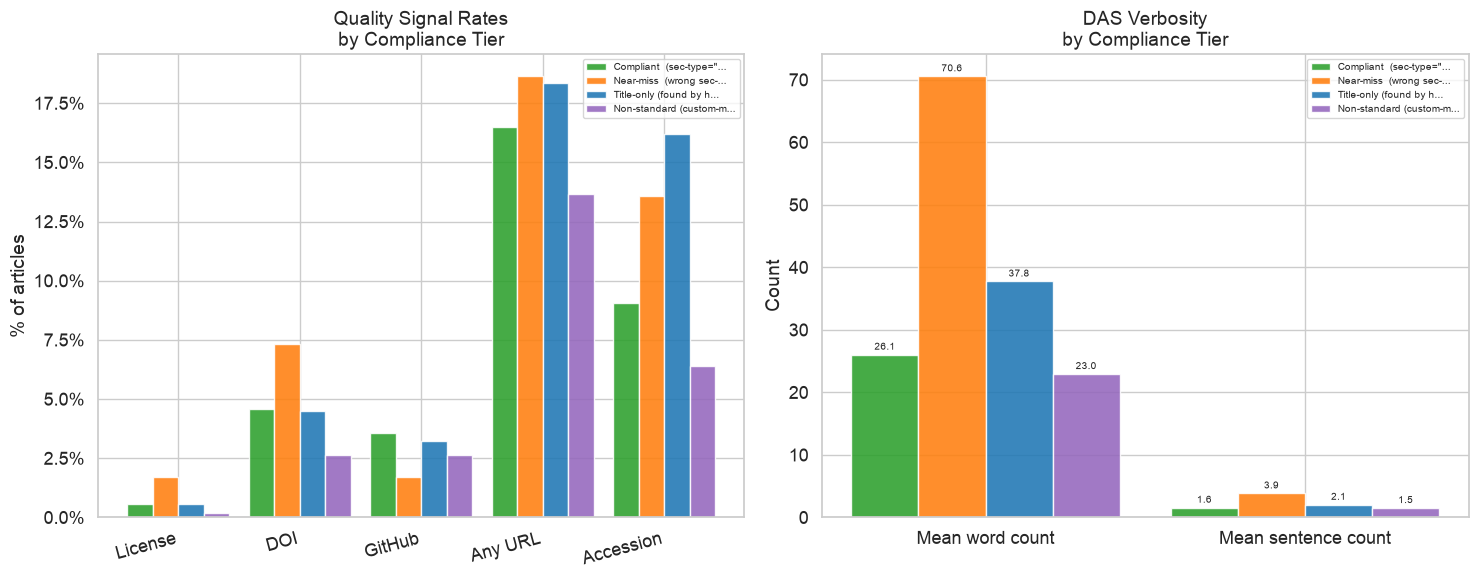

Quality signal rates (%):
               mentions_license  mentions_doi  mentions_github  has_url  has_accession
compliance                                                                           
compliant                 0.57          4.57             3.59    16.49           9.07
near_miss                 1.69          7.34             1.69    18.64          13.56
title_only                0.56          4.51             3.24    18.34          16.19
non_standard              0.19          2.64             2.65    13.66           6.40


In [11]:
SIGS = ['mentions_license','mentions_doi','mentions_github','has_url','has_accession']
SIG_LBL = {
    'mentions_license':'License', 'mentions_doi':'DOI',
    'mentions_github':'GitHub', 'has_url':'Any URL', 'has_accession':'Accession',
}
sig_mean = (df[df['compliance'].isin(tiers_4)]
            .groupby('compliance')[SIGS + ['word_count','sentence_count']]
            .mean().reindex(tiers_4))
sig_pct  = sig_mean[SIGS] * 100

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 1))

ax = axes[0]
xs = np.arange(len(SIGS)); w = 0.21
for i, t in enumerate(tiers_4):
    if t not in sig_pct.index:
        continue
    ax.bar(xs + (i-1.5)*w, [sig_pct.loc[t,c] for c in SIGS], w,
           label=C_LABEL[t][:22]+'...', color=C_PAL[t], alpha=0.88, edgecolor='white')
ax.set_xticks(xs)
ax.set_xticklabels([SIG_LBL[c] for c in SIGS], rotation=15, ha='right')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% of articles'); ax.legend(fontsize=7)
ax.set_title('Quality Signal Rates\nby Compliance Tier')

ax = axes[1]
xv = np.arange(2); wv = 0.21
for i, t in enumerate(tiers_4):
    if t not in sig_mean.index:
        continue
    vals = [sig_mean.loc[t,'word_count'], sig_mean.loc[t,'sentence_count']]
    b = ax.bar(xv + (i-1.5)*wv, vals, wv,
               label=C_LABEL[t][:22]+'...', color=C_PAL[t], alpha=0.88, edgecolor='white')
    ax.bar_label(b, fmt='{:.1f}', padding=2, fontsize=7)
ax.set_xticks(xv)
ax.set_xticklabels(['Mean word count','Mean sentence count'])
ax.set_ylabel('Count'); ax.legend(fontsize=7)
ax.set_title('DAS Verbosity\nby Compliance Tier')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_jats4r_06_quality.png", **SAVEFIG_KWARGS)
plt.show()
print("Quality signal rates (%):\n", sig_pct.round(2).to_string())


---
## §7 - DAS Text Content by Compliance Tier

JATS4R compliance concerns the XML container. This section asks whether
compliant publishers also write informationally richer statements - i.e.,
whether XML quality and prose quality co-vary.

Eight keyword patterns probe distinct data-sharing behaviours:
named repository, DOI in text, accession number, license, "available on
request", GitHub link, reproducibility language, "no data generated".


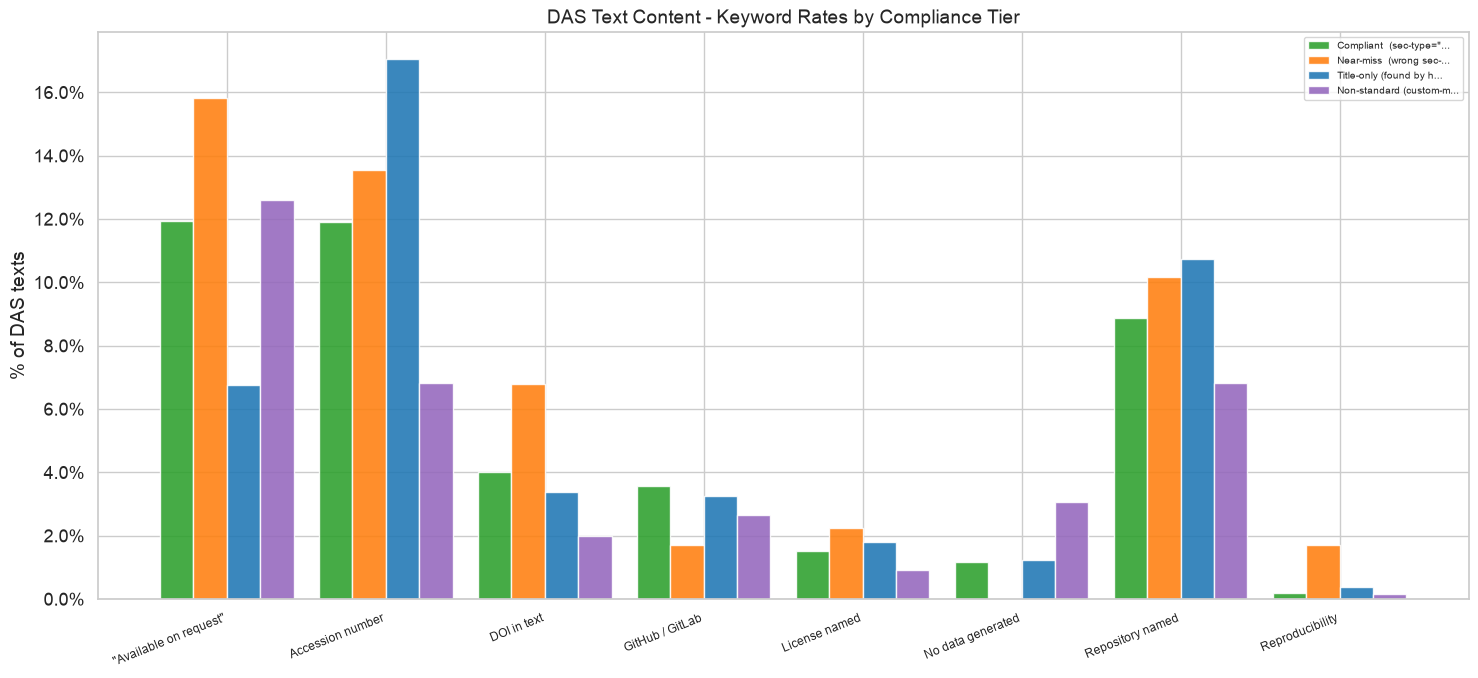

tier                    compliant  near_miss  title_only  non_standard
keyword                                                               
"Available on request"      11.94      15.82        6.75         12.61
Accession number            11.91      13.56       17.06          6.84
DOI in text                  4.02       6.78        3.39          1.99
GitHub / GitLab              3.59       1.69        3.24          2.65
License named                1.51       2.26        1.80          0.91
No data generated            1.18       0.00        1.25          3.06
Repository named             8.87      10.17       10.74          6.82
Reproducibility              0.19       1.69        0.38          0.16


In [12]:
KW = [
    ('Repository named',  r'zenodo|figshare|dryad|osf\.io|dataverse|mendeley.?data|pangaea|arrayexpress|gene.?expression.?omnibus|\bGEO\b'),
    ('DOI in text',       r'doi\.org|https?://doi'),
    ('Accession number',  r'accession|GSE\d+|PRJNA\d+|E-[A-Z]{4}-\d+|PRJEB\d+'),
    ('License named',     r'licen[cs]e|cc.?by|creative.?commons|cc0'),
    ('"Available on request"', r'available.{0,12}(upon|on).{0,12}request'),
    ('GitHub / GitLab',   r'github\.com|gitlab\.com'),
    ('Reproducibility',   r'reproduci'),
    ('No data generated', r'no data.{0,20}(generat|analys|creat)'),
]

kw_rows = []
for tier in tiers_4:
    texts = df[df['compliance'] == tier]['das_text'].fillna('')
    for kw_name, pat in KW:
        rate = texts.str.contains(pat, case=False, regex=True).mean() * 100
        kw_rows.append({'tier': tier, 'keyword': kw_name, 'rate': rate})

df_kw  = pd.DataFrame(kw_rows)
kw_piv = (df_kw.pivot_table(index='keyword', columns='tier', values='rate')
          .reindex(columns=[t for t in tiers_4 if t in df_kw['tier'].unique()]))

fig, ax = plt.subplots(figsize=(FIG_W + 2, FIG_H + 2))
xk = np.arange(len(kw_piv)); wk = 0.21
for i, t in enumerate(kw_piv.columns):
    ax.bar(xk + (i-1.5)*wk, kw_piv[t].values, wk,
           label=C_LABEL[t][:22]+'...', color=C_PAL[t], alpha=0.88, edgecolor='white')
ax.set_xticks(xk)
ax.set_xticklabels(kw_piv.index, rotation=22, ha='right', fontsize=8.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% of DAS texts'); ax.legend(fontsize=7.5)
ax.set_title('DAS Text Content - Keyword Rates by Compliance Tier')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_jats4r_07_text_content.png", **SAVEFIG_KWARGS)
plt.show()
print(kw_piv.round(2).to_string())


---
## §8 - Publisher Compliance League Table

Several JATS4R founding members chair or sit on the DAS subgroup (eLife,
PLoS, SpringerNature, Elsevier, MIT Press). Their own journals should
lead on adoption. We rank every publisher with ≥50 articles by compliance
rate, then separately show the lowest performers among publishers that
*do* include DAS statements (so we exclude publishers with no DAS at all
from the worst list).


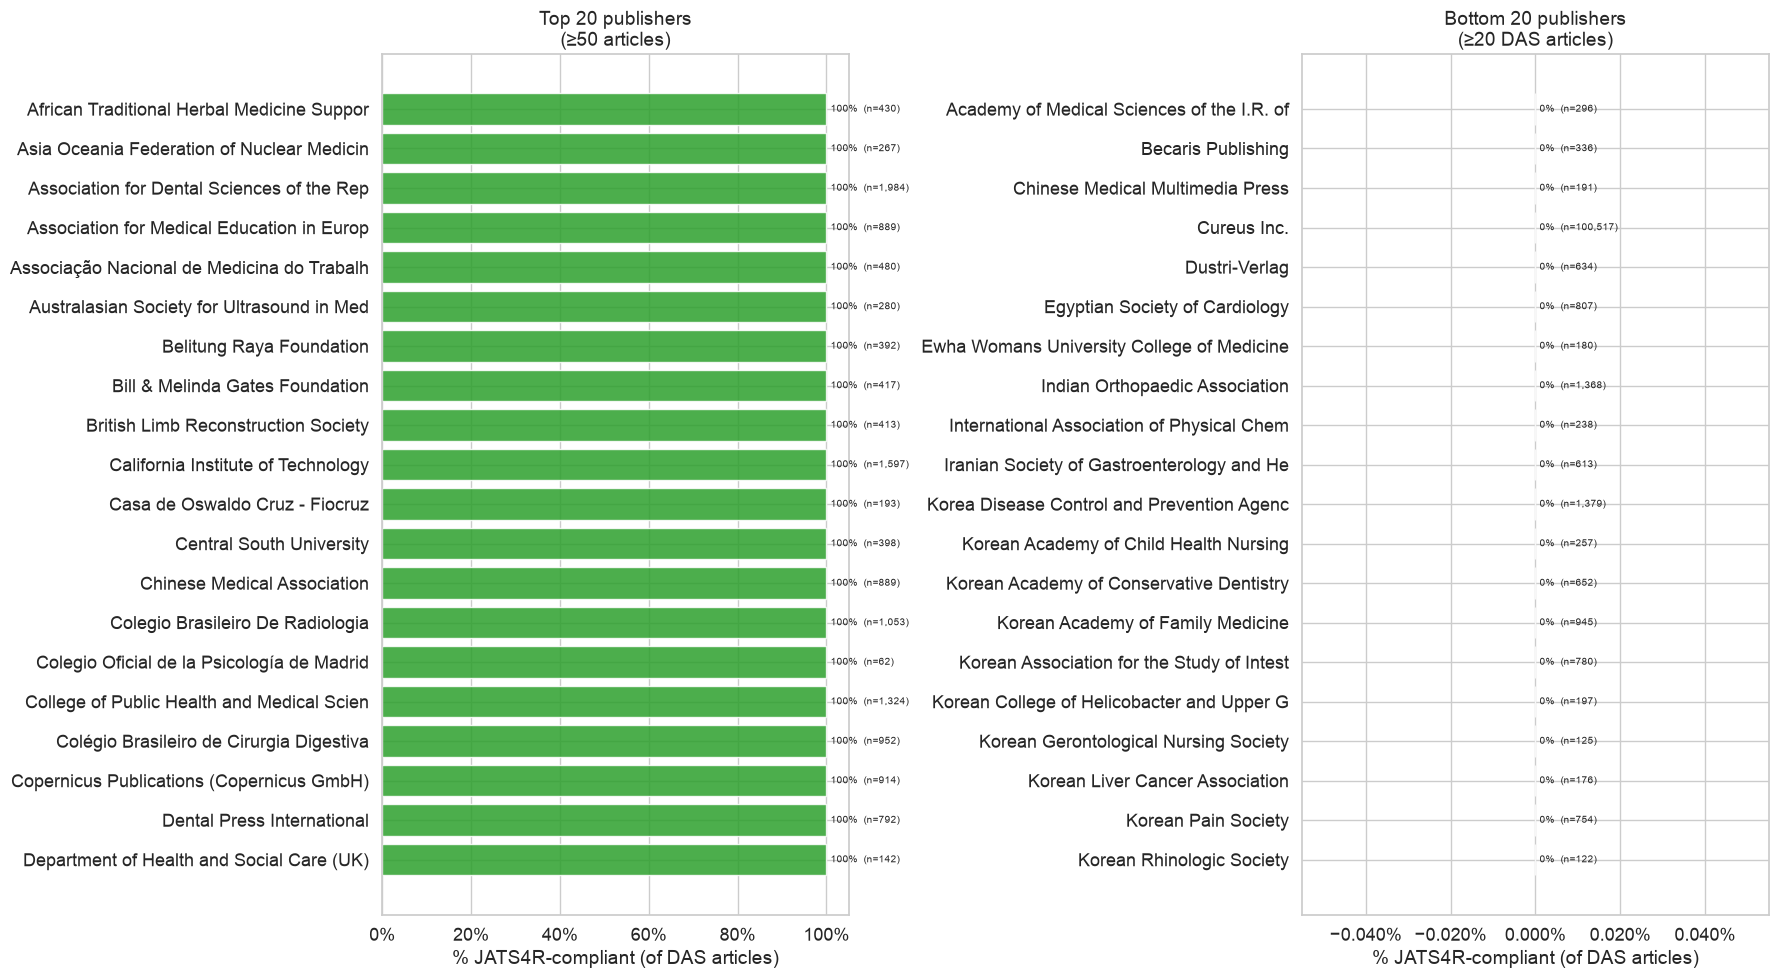

In [13]:
pub = (df.groupby('publisher').agg(
    n_total=('article_id','count'),
    n_das=('has_das','sum'),
    n_comp=('is_compliant','sum'),
    n_near=('compliance', lambda x: (x=='near_miss').sum()),
    mean_score=('data_sharing_score','mean')
).reset_index())
pub['pct_das']  = pub['n_das']  / pub['n_total']       * 100
pub['pct_comp'] = pub['n_comp'] / pub['n_das'].clip(1)  * 100
pub['pct_near'] = pub['n_near'] / pub['n_das'].clip(1)  * 100
pub50 = pub[pub['n_total'] >= 50].copy()
pub50['short'] = pub50['publisher'].apply(lambda p: str(p or '(unknown)')[:42])

top20 = pub50.nlargest(20, 'pct_comp')
bot20 = pub50[pub50['n_das'] >= 20].nsmallest(20, 'pct_comp')

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 5, FIG_H + 5))
for ax, sub, title, clr in [
        (axes[0], top20, 'Top 20 publishers\n(≥50 articles)', '#2ca02c'),
        (axes[1], bot20, 'Bottom 20 publishers\n(≥20 DAS articles)', '#ff7f0e')]:
    bars = ax.barh(sub['short'][::-1], sub['pct_comp'][::-1],
                   color=clr, alpha=0.85, edgecolor='white')
    ax.bar_label(bars,
                 labels=[f"{v:.0f}%  (n={int(n):,})"
                         for v, n in zip(sub['pct_comp'][::-1], sub['n_total'][::-1])],
                 padding=3, fontsize=7.5)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_xlabel('% JATS4R-compliant (of DAS articles)')
    ax.set_title(title)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_jats4r_08_publisher.png", **SAVEFIG_KWARGS)
plt.show()


---
## §9 - Compliance by OA Tier

Gold OA publishers - especially diamond/no-APC journals - often build XML
production in-house for their own web rendering and typically adopt standards
sooner. Subscription publishers produce JATS mainly for repository deposit
and may lag on template updates.


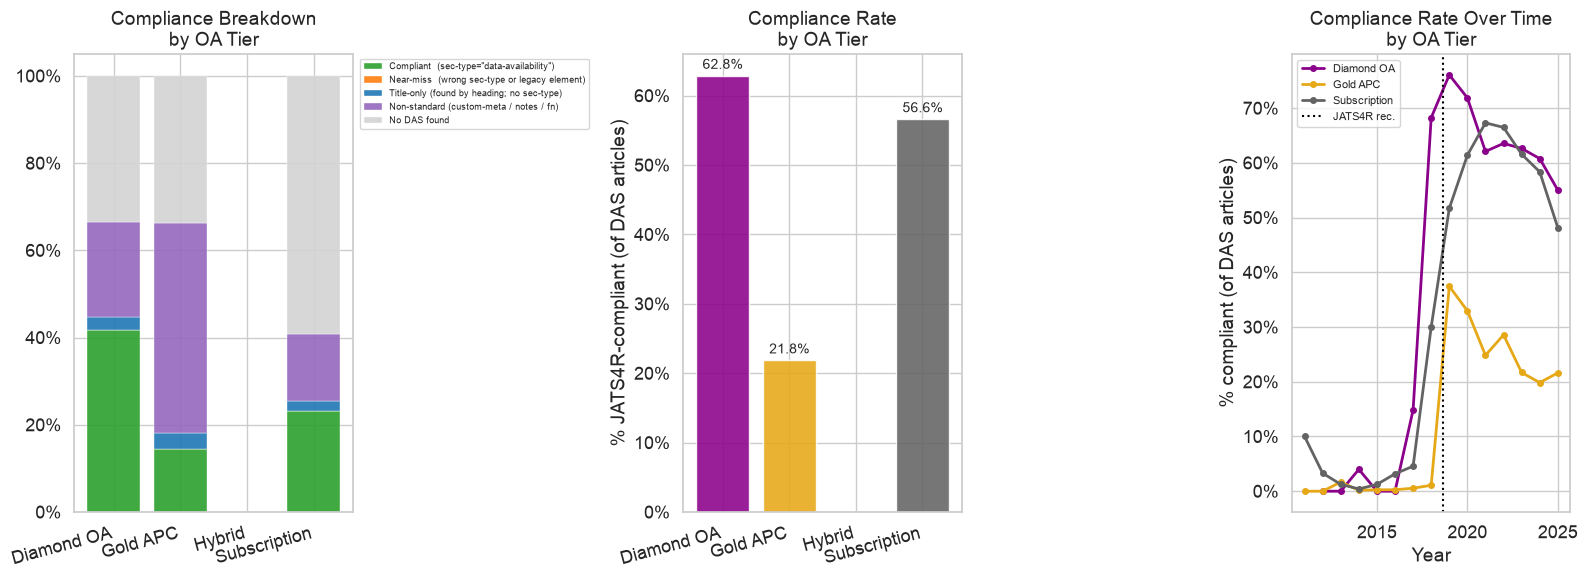

     oa_tier   n_total  pct_das  pct_comp  mean_score
  diamond_oa   39140.0    66.53     62.85        5.66
    gold_apc 2491562.0    66.23     21.84        4.06
      hybrid       NaN      NaN       NaN         NaN
subscription 1416120.0    40.83     56.58        3.92


In [14]:
if not HAS_OA:
    print("Skipped - OA status data not available in this database.")
else:
    _DIAM_ISSNS = {
        '1860-5397','2190-4286','1680-7316','1991-9603','1866-3508',
        '1994-0416','1726-4189','2050-084X','2398-502X','2399-3642','2046-2441'}
    _DIAM_RE   = re.compile(
        r'beilstein|wellcome open|gates open|atmospheric chemistry|'
        r'geoscientific model|earth system science|the cryosphere|'
        r'biogeosciences|ocean science|solid earth|open biology|elife', re.I)
    _GOLD_RE   = re.compile(
        r'\bplos\b|biomed central|\bbmc\b|\bfrontiers\b|\bmdpi\b|\bhindawi\b|\bpeerj\b', re.I)

    df_joa = qdb("""SELECT j.journal_id, j.title, j.publisher, j.issn_epub, j.issn_ppub,
                   COALESCE(jo.oa_status,'unknown') AS oa_status
            FROM journal j LEFT JOIN journal_oa jo ON jo.journal_id=j.journal_id""")
    def _tier(r):
        t  = (str(r.get('title','') or '') + ' ' + str(r.get('publisher','') or '')).lower()
        ie = str(r.get('issn_epub','') or '')
        ip = str(r.get('issn_ppub','') or '')
        if ie in _DIAM_ISSNS or ip in _DIAM_ISSNS: return 'diamond_oa'
        if _DIAM_RE.search(t): return 'diamond_oa'
        if r.get('oa_status') == 'gold_oa': return 'gold_apc'
        # journal_oa.oa_status stores 'likely_subscription' (and sometimes
        # 'not_listed_in_doaj'), not the literal 'subscription' OA_ORD below
        # expects -- without this mapping, every such journal fell outside
        # OA_ORD entirely and was silently dropped from every tier-stratified
        # stat in this cell (same bug, independently discovered and fixed in
        # 07_diamond_oa.ipynb's classify_oa()).
        if r.get('oa_status') == 'likely_subscription': return 'subscription'
        return str(r.get('oa_status','unknown') or 'unknown')
    df_joa['oa_tier'] = df_joa.apply(_tier, axis=1)
    df2 = df.merge(df_joa[['journal_id','oa_tier']], on='journal_id', how='left')
    df2['oa_tier'] = df2['oa_tier'].fillna('unknown')

    OA_ORD = ['diamond_oa','gold_apc','hybrid','subscription']
    OA_LBL = {'diamond_oa':'Diamond OA','gold_apc':'Gold APC',
               'hybrid':'Hybrid','subscription':'Subscription'}
    OA_PAL = {'diamond_oa':'#8b008b','gold_apc':'#e6a817',
               'hybrid':'#4292c6','subscription':'#636363'}

    oa_c = (df2[df2['oa_tier'].isin(OA_ORD)].groupby('oa_tier').agg(
        n_total=('article_id','count'), n_das=('has_das','sum'),
        n_comp=('is_compliant','sum'),  mean_score=('data_sharing_score','mean')
    ).reindex(OA_ORD).reset_index())
    oa_c['pct_das']  = oa_c['n_das']  / oa_c['n_total']      * 100
    oa_c['pct_comp'] = oa_c['n_comp'] / oa_c['n_das'].clip(1) * 100

    oa_t_c = (df2[df2['oa_tier'].isin(OA_ORD)]
              .groupby(['oa_tier','compliance']).size().reset_index(name='n'))
    oa_tot = df2[df2['oa_tier'].isin(OA_ORD)].groupby('oa_tier').size()
    oa_t_c['pct'] = oa_t_c.apply(lambda r: r['n']/oa_tot.get(r['oa_tier'],1)*100, axis=1)
    piv_oa = (oa_t_c.pivot_table(index='oa_tier', columns='compliance',
                                   values='pct', aggfunc='sum')
              .fillna(0).reindex(OA_ORD))

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 3, FIG_H + 1))

    ax = axes[0]
    bot = np.zeros(len(piv_oa))
    for t in C_ORDER:
        if t not in piv_oa.columns: continue
        ax.bar([OA_LBL[k] for k in OA_ORD], piv_oa[t].values, bottom=bot,
               color=C_PAL[t], label=C_LABEL[t], edgecolor='white', lw=0.3, alpha=0.9)
        bot += piv_oa[t].values
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title('Compliance Breakdown\nby OA Tier')
    ax.legend(fontsize=6.5, bbox_to_anchor=(1.01,1), loc='upper left')
    ax.set_xticklabels([OA_LBL[k] for k in OA_ORD], rotation=15, ha='right')

    ax = axes[1]
    b = ax.bar([OA_LBL[k] for k in OA_ORD], oa_c['pct_comp'],
               color=[OA_PAL[k] for k in OA_ORD], alpha=0.88, edgecolor='white')
    ax.bar_label(b, fmt='{:.1f}%', padding=3, fontsize=10)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_ylabel('% JATS4R-compliant (of DAS articles)')
    ax.set_title('Compliance Rate\nby OA Tier')
    ax.set_xticklabels([OA_LBL[k] for k in OA_ORD], rotation=15, ha='right')

    ax = axes[2]
    for k in OA_ORD:
        sub = df2[(df2['oa_tier']==k) & df2['has_das']]
        if len(sub) == 0: continue
        yr_c = sub.groupby('year')['is_compliant'].mean() * 100
        ax.plot(yr_c.index, yr_c.values, lw=2, marker='o', ms=4,
                color=OA_PAL[k], label=OA_LBL[k])
    ax.axvline(2018.67, color='black', lw=1.5, ls=':', label='JATS4R rec.')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_xlabel('Year'); ax.set_ylabel('% compliant (of DAS articles)')
    ax.set_title('Compliance Rate Over Time\nby OA Tier')
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_jats4r_09_oa_tier.png", **SAVEFIG_KWARGS)
    plt.show()
    print(oa_c[['oa_tier','n_total','pct_das','pct_comp','mean_score']].round(2).to_string(index=False))


---
## §10 - Compliance by Discipline  *(Stage 6)*

Fields with a long tradition of structured data deposit (genomics,
structural biology, clinical trials) may or may not translate that
culture into JATS4R compliance - the XML production chain sits with
the publisher, not the authors.


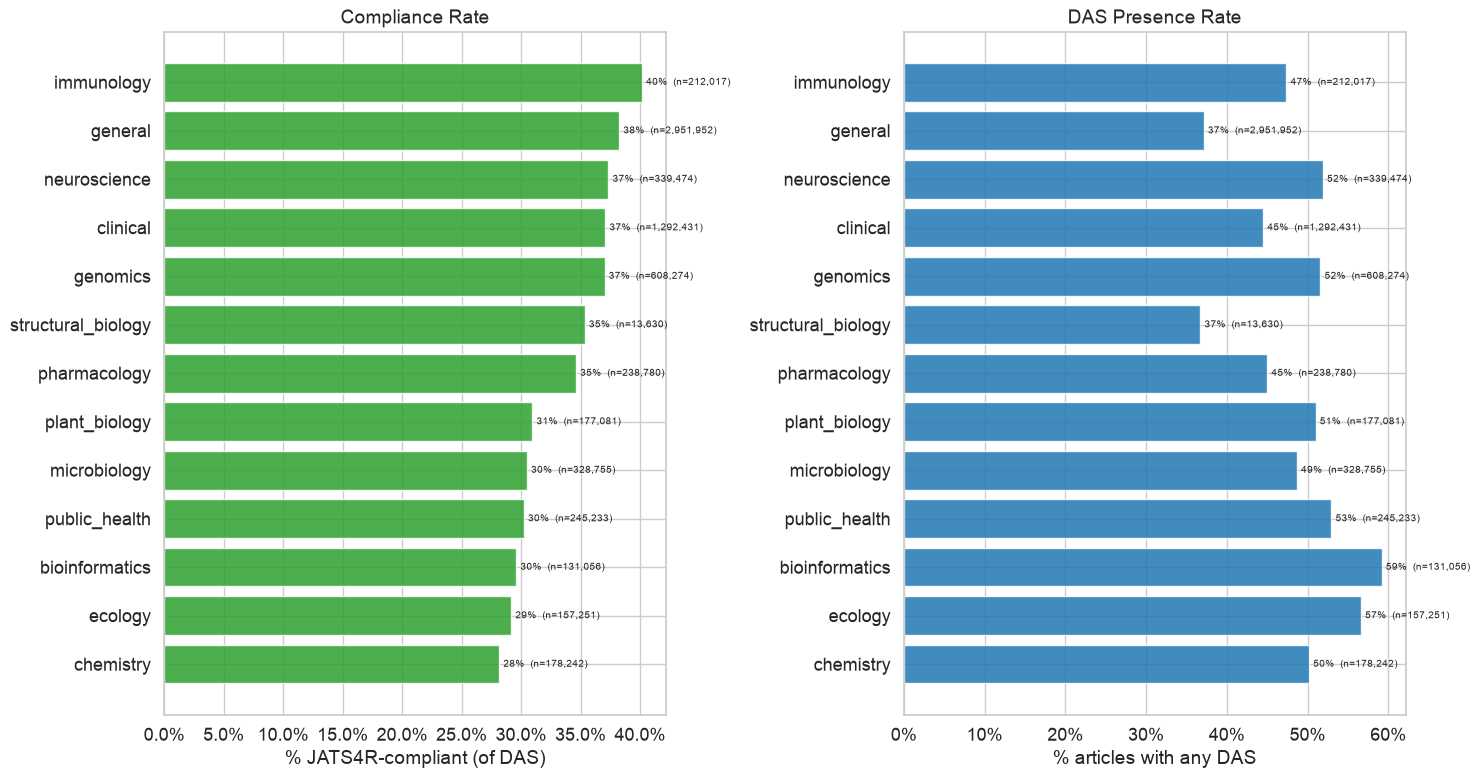

In [15]:
if not HAS_DISC:
    print("Skipped - discipline data not available in this database.")
else:
    # Discipline covers ~all articles 1:1 (PK=article_id) -- no need to re-join
    # article here, df is already year-filtered; the inner merge does it.
    df_d = qdb("SELECT article_id, discipline FROM article_discipline")
    df_d = df[['article_id','is_compliant','has_das','data_sharing_score']].merge(df_d, on='article_id')
    disc = (df_d.groupby('discipline').agg(
        n_total=('article_id','count'), n_das=('has_das','sum'),
        n_comp=('is_compliant','sum'),  mean_score=('data_sharing_score','mean')
    ).reset_index())
    disc['pct_das']  = disc['n_das']  / disc['n_total']      * 100
    disc['pct_comp'] = disc['n_comp'] / disc['n_das'].clip(1) * 100
    disc = disc.sort_values('pct_comp', ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 3))
    for ax, col, xlabel, clr, title in [
            (axes[0],'pct_comp','% JATS4R-compliant (of DAS)','#2ca02c','Compliance Rate'),
            (axes[1],'pct_das', '% articles with any DAS',     '#1f77b4','DAS Presence Rate')]:
        bars = ax.barh(disc['discipline'][::-1], disc[col][::-1],
                       color=clr, alpha=0.85, edgecolor='white')
        ax.bar_label(bars,
                     labels=[f"{v:.0f}%  (n={int(n):,})"
                             for v,n in zip(disc[col][::-1], disc['n_total'][::-1])],
                     padding=3, fontsize=7.5)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter())
        ax.set_xlabel(xlabel); ax.set_title(title)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_jats4r_10_discipline.png", **SAVEFIG_KWARGS)
    plt.show()


---
## §11 - Compliance by Funder  *(Stage 6)*

Funders with strong open-science mandates (Wellcome Trust, NIH, ERC,
cOAlition S members) sometimes specify exact DAS wording. Do their
grantees publish in more JATS4R-compliant journals?


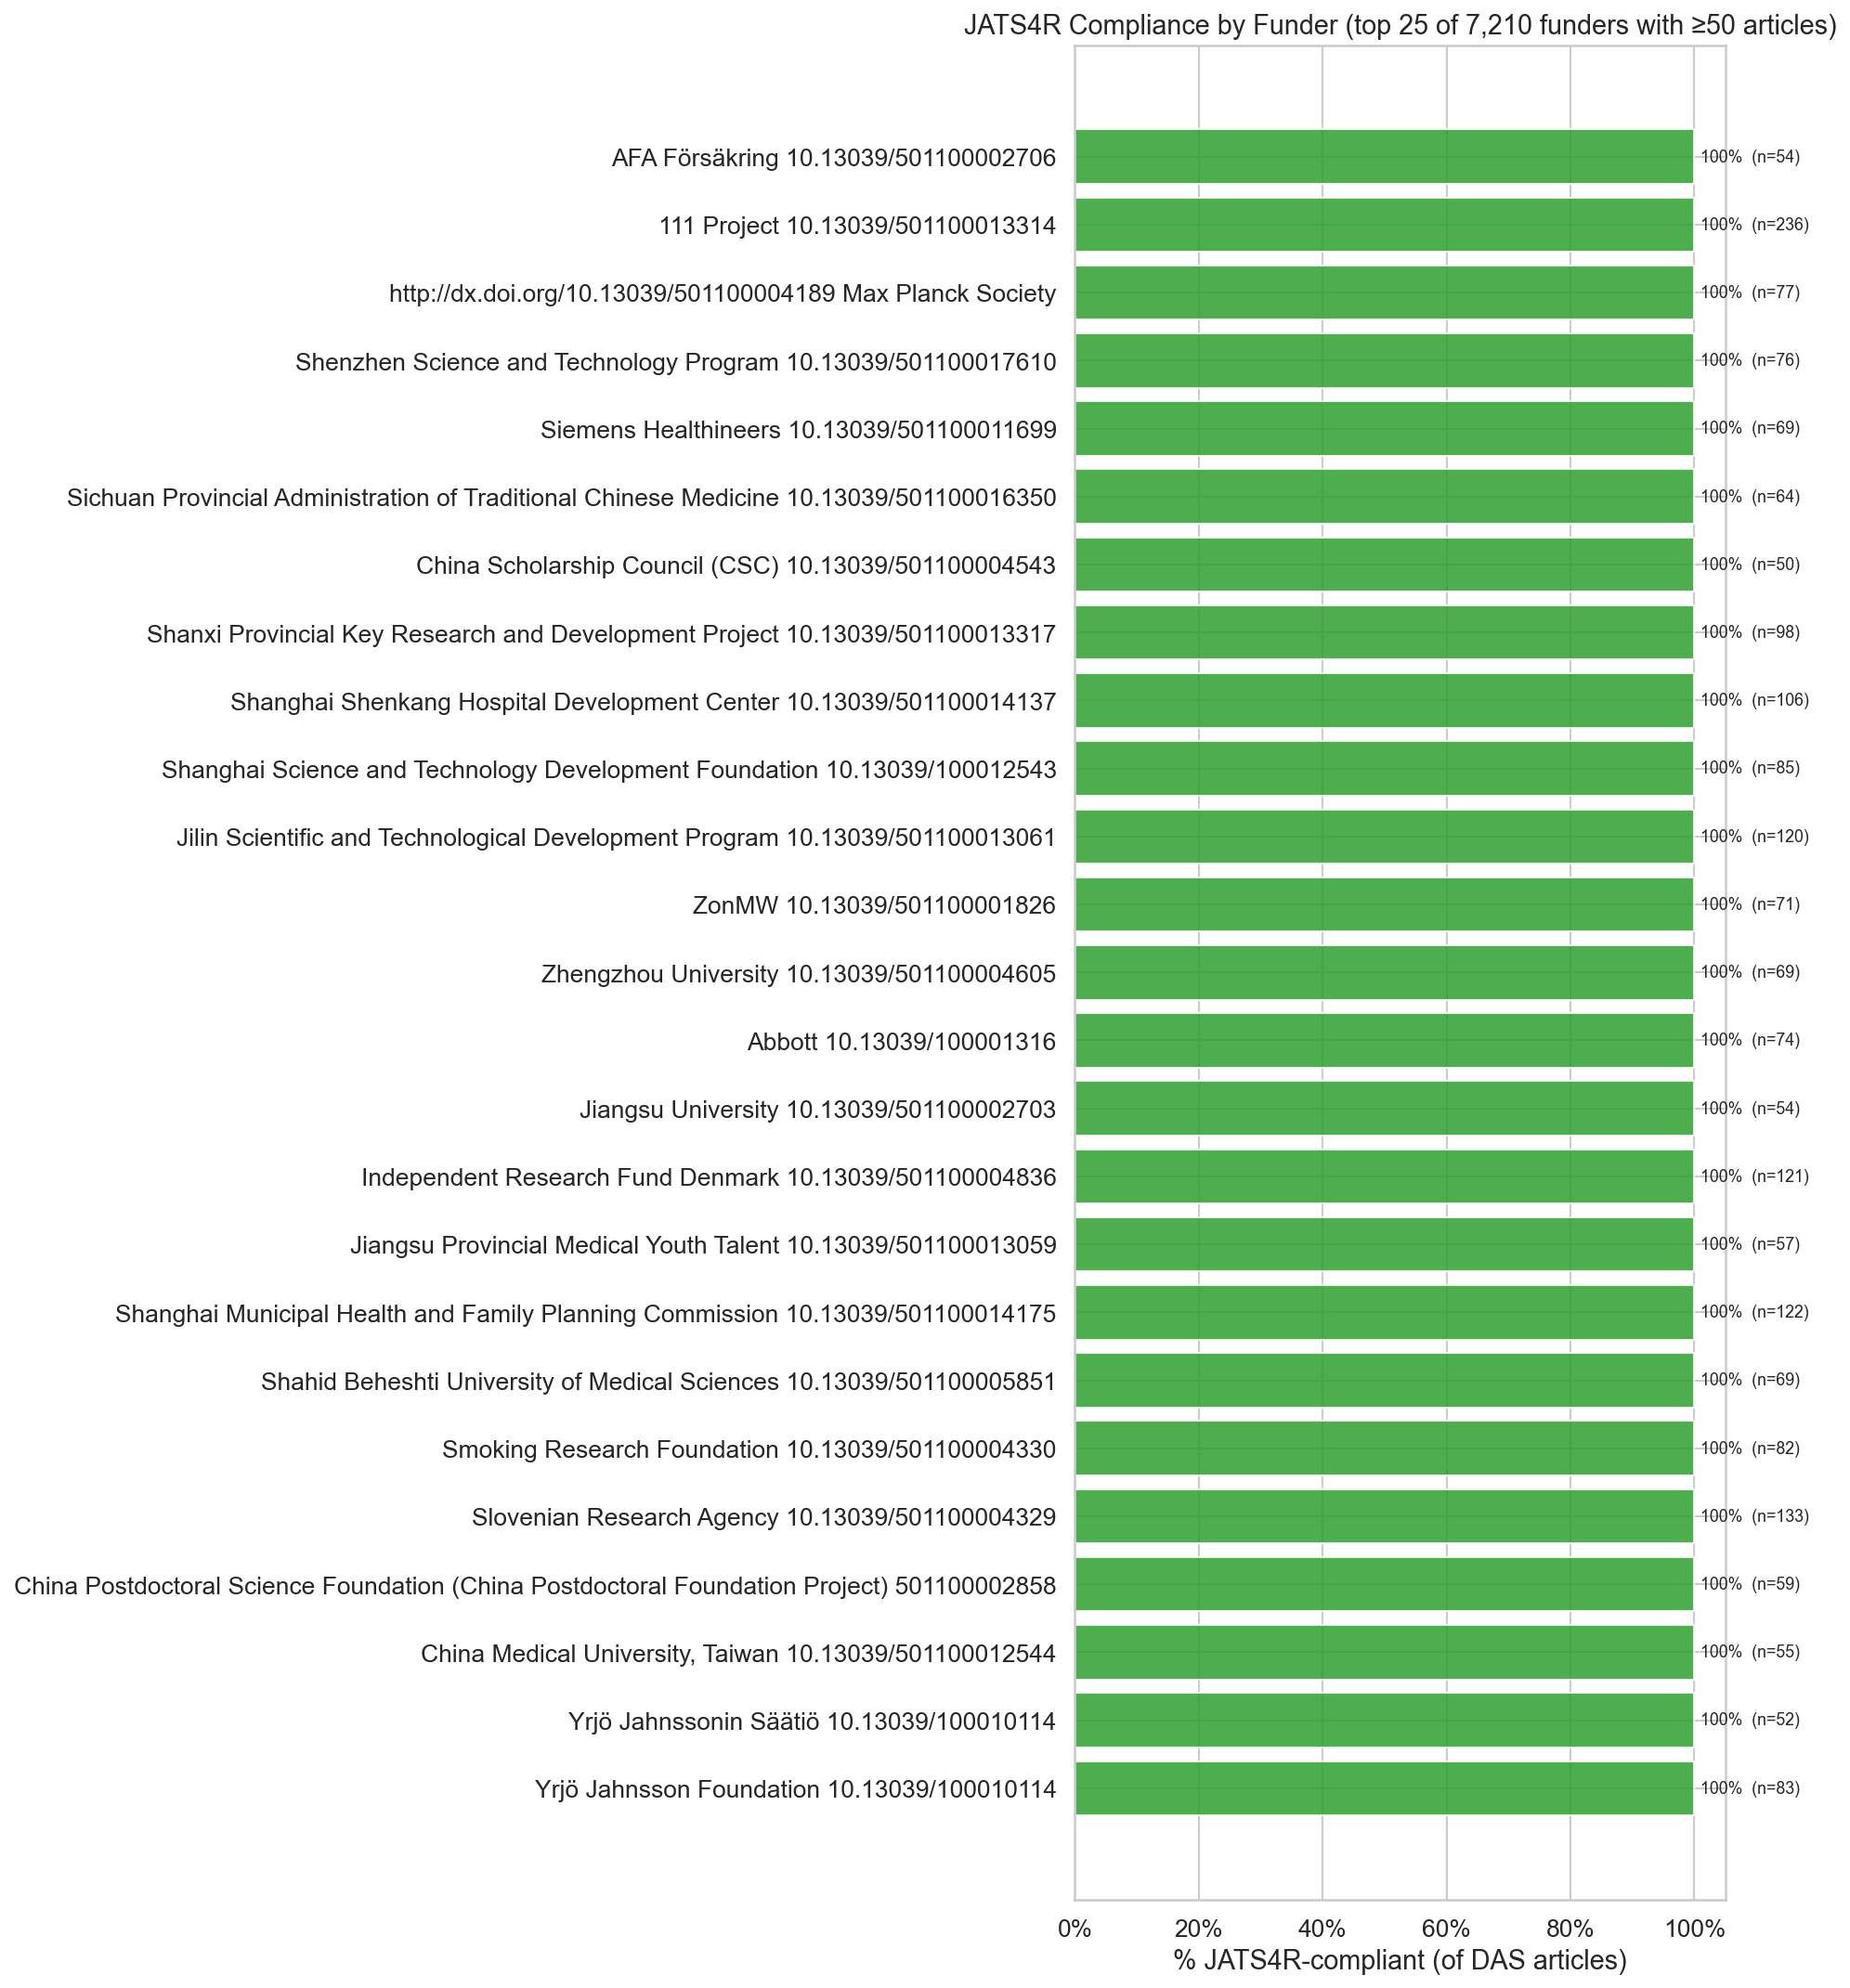

In [16]:
if not HAS_FUNDER:
    print("Skipped - funder data not available in this database.")
else:
    # df is already year-filtered; the inner merge restricts to it, so no need
    # to re-join article here.
    df_f = qdb("SELECT article_id, funder_norm FROM article_funder WHERE funder_norm != 'none'")
    df_f = df[['article_id','is_compliant','has_das','data_sharing_score']].merge(df_f, on='article_id')
    fund = (df_f.groupby('funder_norm').agg(
        n_total=('article_id', pd.Series.nunique),
        n_das=('has_das','sum'), n_comp=('is_compliant','sum'),
        mean_score=('data_sharing_score','mean')
    ).reset_index())
    fund['pct_comp'] = fund['n_comp'] / fund['n_das'].clip(1) * 100
    fund = fund[fund['n_total'] >= 50].sort_values('pct_comp', ascending=False)
    n_qualifying = len(fund)
    # Cap to top 25 (same convention as the funder panel in
    # 08_mandate_compliance.ipynb) -- plotting all ~7,200 funders that clear
    # the >=50-article bar produced a 560,000px-tall, 95MB, unreadable PNG.
    fund = fund.head(25)

    fig, ax = plt.subplots(figsize=(FIG_W, max(5, len(fund)*0.52+1.5)))
    bars = ax.barh(fund['funder_norm'][::-1], fund['pct_comp'][::-1],
                   color='#2ca02c', alpha=0.85, edgecolor='white')
    ax.bar_label(bars,
                 labels=[f"{v:.0f}%  (n={int(n):,})"
                         for v,n in zip(fund['pct_comp'][::-1], fund['n_total'][::-1])],
                 padding=3, fontsize=8.5)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_xlabel('% JATS4R-compliant (of DAS articles)')
    ax.set_title(f'JATS4R Compliance by Funder (top 25 of {n_qualifying:,} funders with ≥50 articles)')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_jats4r_11_funder.png", **SAVEFIG_KWARGS)
    plt.show()


---
## §12 - Four-Period Analysis

| Period | Years | Significance |
|--------|-------|--------------|
| Pre-FAIR | 2011-2015 | Baseline - no DAS norm, no JATS4R |
| FAIR year | 2016 | Wilkinson et al. paper published |
| Post-FAIR / pre-rec | 2017-2018 | Awareness raised but no JATS4R spec yet |
| Post-rec | 2019-2025 | JATS4R DAS rec. published Dec 2018 |

Before December 2018 no article could be JATS4R-compliant - the authoritative
`sec-type` value had not been published. Any articles showing a compliant
source in earlier years reflect either backdated indexing or forward-dating.


                     Period  Articles  With DAS  DAS %  Compliant  Compliant % (DAS)  Near-miss % (DAS)  Mean Score
         Pre-FAIR (2011-15)    922067     58496    6.3        151                0.3                0.0       4.507
           FAIR year (2016)    277445     50691   18.3        211                0.4                0.0       4.433
Post-FAIR / pre-rec (17-18)    667672    164589   24.7       8408                5.1                0.0       4.358
         Post-rec (2019-24)   5006992   2737267   54.7    1075535               39.3                0.0       3.859


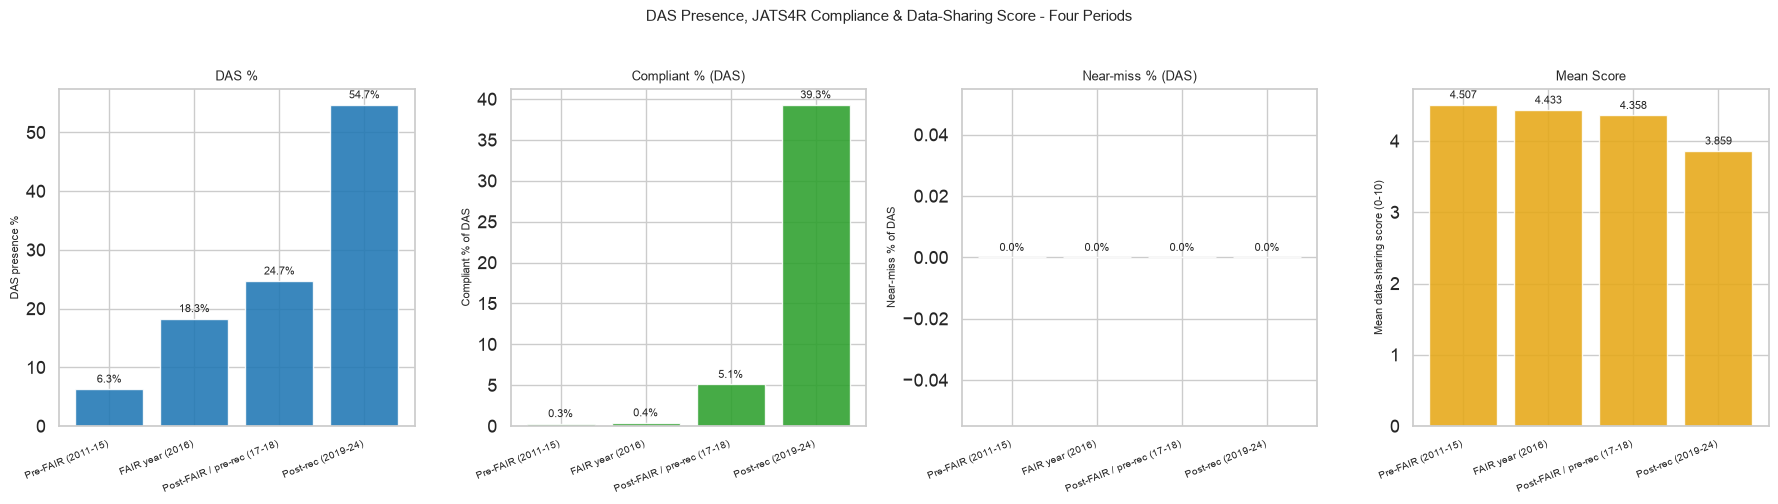

In [17]:
PERIOD_DEF = [
    ('Pre-FAIR (2011-15)',          df['year'] < 2016),
    ('FAIR year (2016)',            df['year'] == 2016),
    ('Post-FAIR / pre-rec (17-18)', df['year'].between(2017, 2018)),
    ('Post-rec (2019-24)',          df['year'] > 2018),
]
rows = []
for label, mask in PERIOD_DEF:
    sub = df[mask]
    if len(sub) == 0: continue
    nd = sub['has_das'].sum()
    nc = sub['is_compliant'].sum()
    nn = (sub['compliance'] == 'near_miss').sum()
    rows.append({
        'Period': label, 'Articles': len(sub),
        'With DAS': int(nd), 'DAS %': round(nd/len(sub)*100,1),
        'Compliant': int(nc), 'Compliant % (DAS)': round(nc/max(nd,1)*100,1),
        'Near-miss % (DAS)': round(nn/max(nd,1)*100,1),
        'Mean Score': round(sub['data_sharing_score'].mean(),3),
    })
df_per = pd.DataFrame(rows)
print(df_per.to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(FIG_W + 5, FIG_H))
metrics = [
    ('DAS %',              'DAS presence %',        '#1f77b4'),
    ('Compliant % (DAS)',  'Compliant % of DAS',    '#2ca02c'),
    ('Near-miss % (DAS)',  'Near-miss % of DAS',    '#ff7f0e'),
    ('Mean Score',          'Mean data-sharing score (0-10)','#e6a817'),
]
for ax, (col, ylabel, clr) in zip(axes, metrics):
    bars = ax.bar(range(len(df_per)), df_per[col],
                  color=clr, alpha=0.88, edgecolor='white')
    fmt = '{:.1f}%' if '%' in col else '{:.3f}'
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=8)
    ax.set_xticks(range(len(df_per)))
    ax.set_xticklabels(df_per['Period'], rotation=22, ha='right', fontsize=7)
    ax.set_ylabel(ylabel, fontsize=8); ax.set_title(col, fontsize=9)
plt.suptitle('DAS Presence, JATS4R Compliance & Data-Sharing Score - Four Periods',
             fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_jats4r_12_periods.png", **SAVEFIG_KWARGS)
plt.show()


---
## §13 - DAS Link Types and Data-Citation Structure

JATS4R Rule 5 requires `@publication-type="data"` on every
`<element-citation>` / `<mixed-citation>` that references a dataset -
making data citations machine-readable for Crossref, Google Scholar,
and data repositories.

The pipeline records the XML element that produced each `da_link` row in
`da_link.link_type`: `uri` and `text-url` are bare links; `related-object`,
`element-citation`, and `mixed-citation` are structured citations.


DAS link type distribution:
                  link_type      n   pct
                        uri 938059 80.38
             pmc:entrez-geo  84768  7.26
      pmc:entrez-nucleotide  54970  4.71
                   text-url  40854  3.50
          DDBJ/EMBL/GenBank  20169  1.73
pmc:entrez-nucleotide-range  11845  1.01
                        doi   5358  0.46
         pmc:entrez-protein   3919  0.34
         pmc:clinical-trial   1521  0.13
                        PDB   1458  0.12
                        gen   1117  0.10
                        ftp    929  0.08
                   NCBI:sra    553  0.05
                   NCBI:geo    437  0.04
                      pride    401  0.03
                    EBI:ena    106  0.01
           EBI:arrayexpress     85  0.01
               NCBI:protein     84  0.01
                        pdb     63  0.01
            NCBI:nucleotide     55  0.00
         ClinicalTrials.gov     48  0.00
                    GenBank     40  0.00
             NCBI:structure  

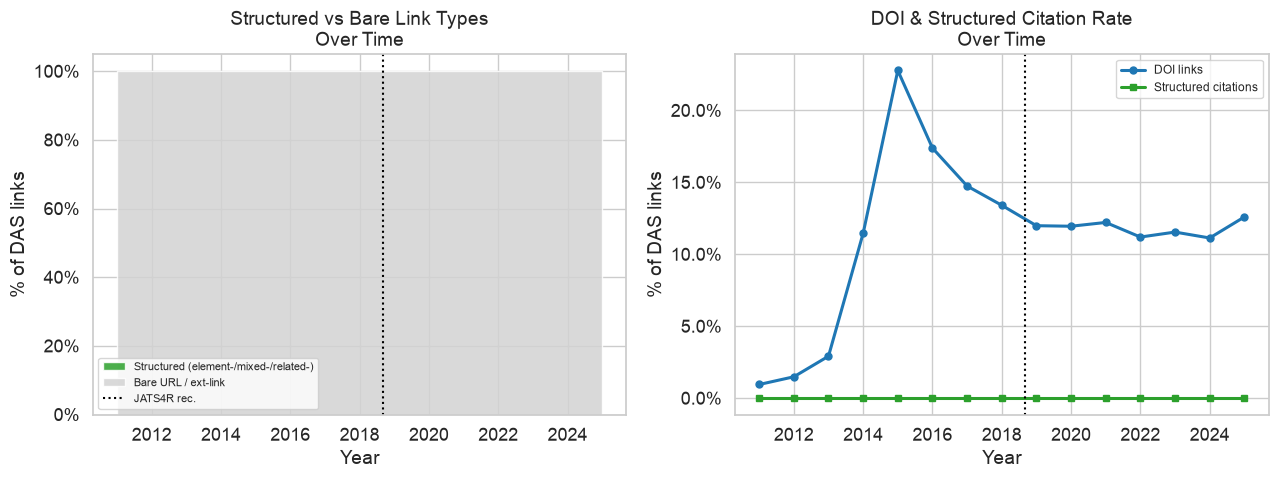

In [18]:
df_lnk = qdb("""SELECT dl.link_id, COALESCE(dl.link_type,'') AS link_type,
               dl.url, da.source,
               a.year AS year
        FROM da_link dl
        JOIN data_availability da ON da.da_id=dl.da_id
        JOIN article a ON a.article_id=da.article_id
        WHERE a.year BETWEEN 2011 AND 2025""")
df_lnk['compliance']   = df_lnk['source'].apply(classify)
df_lnk['is_structured']= df_lnk['link_type'].isin(
    {'related-object','element-citation','mixed-citation'})
df_lnk['is_doi']       = df_lnk['url'].str.contains(r'doi\.org', na=False, regex=True)

lt_vc = df_lnk['link_type'].value_counts().reset_index()
lt_vc.columns = ['link_type','n']
lt_vc['pct'] = lt_vc['n'] / len(df_lnk) * 100

print("DAS link type distribution:")
print(lt_vc.round(2).to_string(index=False))
print(f"\nStructured: {df_lnk['is_structured'].sum():,} ({df_lnk['is_structured'].mean()*100:.1f}%)")
print(f"DOI links : {df_lnk['is_doi'].sum():,} ({df_lnk['is_doi'].mean()*100:.1f}%)")

yr_lnk = (df_lnk.groupby('year').agg(
    n=('link_id','count'), n_struct=('is_structured','sum'), n_doi=('is_doi','sum')
).reset_index())
yr_lnk['pct_struct'] = yr_lnk['n_struct'] / yr_lnk['n'] * 100
yr_lnk['pct_doi']    = yr_lnk['n_doi']    / yr_lnk['n'] * 100

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

ax = axes[0]
ax.stackplot(yr_lnk['year'],
             yr_lnk['pct_struct'], 100-yr_lnk['pct_struct'],
             labels=['Structured (element-/mixed-/related-)','Bare URL / ext-link'],
             colors=['#2ca02c','#d3d3d3'], alpha=0.85)
ax.axvline(2018.67, color='black', lw=1.5, ls=':', label='JATS4R rec.')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Year'); ax.set_ylabel('% of DAS links')
ax.set_title('Structured vs Bare Link Types\nOver Time')
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(yr_lnk['year'], yr_lnk['pct_doi'],    lw=2.2, marker='o', ms=5,
        color='#1f77b4', label='DOI links')
ax.plot(yr_lnk['year'], yr_lnk['pct_struct'],  lw=2.2, marker='s', ms=5,
        color='#2ca02c', label='Structured citations')
ax.axvline(2018.67, color='black', lw=1.5, ls=':')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Year'); ax.set_ylabel('% of DAS links')
ax.set_title('DOI & Structured Citation Rate\nOver Time')
ax.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_jats4r_13_link_types.png", **SAVEFIG_KWARGS)
plt.show()


---
## §14 - Statistical Summary + Exports

In [19]:
# ── Statistical tests ────────────────────────────────────────────────────────
print('='*88)
print('JATS4R DAS COMPLIANCE - STATISTICAL SUMMARY')
print('='*88)

test_pairs = [
    ('Compliant vs Near-miss',
     df[df['compliance']=='compliant' ]['data_sharing_score'].dropna(),
     df[df['compliance']=='near_miss' ]['data_sharing_score'].dropna()),
    ('Compliant vs Title-only',
     df[df['compliance']=='compliant'  ]['data_sharing_score'].dropna(),
     df[df['compliance']=='title_only' ]['data_sharing_score'].dropna()),
    ('Compliant vs Non-standard',
     df[df['compliance']=='compliant'    ]['data_sharing_score'].dropna(),
     df[df['compliance']=='non_standard' ]['data_sharing_score'].dropna()),
]
stat_rows = []
for label, a, b in test_pairs:
    if len(a) < 2 or len(b) < 2:
        print(f"  {label}: insufficient data"); continue
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    r_e  = u / (len(a)*len(b))
    sig  = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
    stat_rows.append({'Comparison':label,'A_mean':round(a.mean(),3),'A_n':len(a),
                      'B_mean':round(b.mean(),3),'B_n':len(b),
                      'delta':round(a.mean()-b.mean(),3),
                      'p':f'{p:.2e}','r':round(r_e,4),'sig':sig})
    print(f"  {label}: A={a.mean():.3f} B={b.mean():.3f} "
          f"Δ={a.mean()-b.mean():+.3f} p={p:.2e} r={r_e:.4f} {sig}")
df_stat = pd.DataFrame(stat_rows)


JATS4R DAS COMPLIANCE - STATISTICAL SUMMARY


  Compliant vs Near-miss: A=3.702 B=3.486 Δ=+0.216 p=2.61e-02 r=0.5471 *
  Compliant vs Title-only: A=3.702 B=4.006 Δ=-0.304 p=1.07e-275 r=0.4751 ***


  Compliant vs Non-standard: A=3.702 B=3.476 Δ=+0.226 p=0.00e+00 r=0.5158 ***


In [20]:
# ── Key-findings box ─────────────────────────────────────────────────────────
n_tot = len(df)
n_das = int(df['has_das'].sum())
n_c   = int(df['is_compliant'].sum())

pre   = df[df['year'] <= 2018]; pst = df[df['year'] > 2018]
pre_c = pre['is_compliant'].sum() / pre['has_das'].sum() * 100  if pre['has_das'].sum()  else 0
pst_c = pst['is_compliant'].sum() / pst['has_das'].sum() * 100  if pst['has_das'].sum() else 0

sc_c = df[df['is_compliant'] ]['data_sharing_score'].mean()
sc_o = df[~df['is_compliant']]['data_sharing_score'].mean()

n_st_vals = df['sec_type_val'].nunique()
n_ti_vals = df['title_val'].nunique()

lines = [
    "+---------------------------------------------------------------------+",
    "|  JATS4R DAS COMPLIANCE - KEY FINDINGS                              |",
    "+---------------------------------------------------------------------+",
    f"|  Corpus articles (2011-2025)    : {n_tot:>9,}                        |",
    f"|  Articles with any DAS          : {n_das:>9,}  ({n_das/n_tot*100:.1f}%)             |",
    f"|  JATS4R-compliant DAS           : {n_c:>9,}  ({n_c/n_das*100:.1f}% of DAS)       |",
    "|                                                                     |",
    f"|  Distinct sec-type values       : {n_st_vals:>9,}                        |",
    f"|  Distinct title variants        : {n_ti_vals:>9,}                        |",
    "|                                                                     |",
    f"|  Compliant pct pre-rec  (<=2018): {pre_c:>8.1f}%                     |",
    f"|  Compliant pct post-rec (>2018) : {pst_c:>8.1f}%                     |",
    f"|  Uplift after recommendation    : {pst_c-pre_c:>+8.1f} pp                   |",
    "|                                                                     |",
    f"|  Mean data-sharing score - compliant    : {sc_c:>9.3f}                        |",
    f"|  Mean data-sharing score - other        : {sc_o:>9.3f}                        |",
    f"|  FAIR uplift from compliance    : {sc_c-sc_o:>+9.3f}                        |",
    "+---------------------------------------------------------------------+",
]
print("\n".join(lines))


+---------------------------------------------------------------------+
|  JATS4R DAS COMPLIANCE - KEY FINDINGS                              |
+---------------------------------------------------------------------+
|  Corpus articles (2011-2025)    : 6,874,176                        |
|  Articles with any DAS          : 3,011,043  (43.8%)             |
|  JATS4R-compliant DAS           : 1,084,305  (36.0% of DAS)       |
|                                                                     |
|  Distinct sec-type values       :        45                        |
|  Distinct title variants        :     6,982                        |
|                                                                     |
|  Compliant pct pre-rec  (<=2018):      3.2%                     |
|  Compliant pct post-rec (>2018) :     39.3%                     |
|  Uplift after recommendation    :    +36.1 pp                   |
|                                                                     |
|  Mean data-

In [21]:
# ── Exports ───────────────────────────────────────────────────────────────────
export_dir = Path('../results/fair_jats4r_exports')
export_dir.mkdir(parents=True, exist_ok=True)

to_export = {
    'article_compliance.csv':   df[['article_id','year','source','compliance',
                                     'is_compliant','data_sharing_score','cat',
                                     'sec_type_val','title_val']],
    'sectype_variants.csv':     st_counts,
    'title_variants.csv':       tv_counts if len(tv_counts) > 0 else pd.DataFrame(),
    'compliance_by_year.csv':   yr_comp,
    'four_period_summary.csv':  df_per,
    'publisher_stats.csv':      pub50[['publisher','n_total','n_das','pct_das',
                                        'n_comp','pct_comp','pct_near','mean_score']],
    'link_types.csv':           lt_vc,
    'statistical_tests.csv':    df_stat,
}
for fname, df_e in to_export.items():
    df_e.to_csv(export_dir / fname, index=False)
    print(f"  Saved {fname}  ({len(df_e):,} rows)")

con.close()
print("\nDone. Connection closed.")


  Saved article_compliance.csv  (6,874,176 rows)
  Saved sectype_variants.csv  (45 rows)
  Saved title_variants.csv  (6,982 rows)
  Saved compliance_by_year.csv  (57 rows)
  Saved four_period_summary.csv  (4 rows)
  Saved publisher_stats.csv  (765 rows)
  Saved link_types.csv  (44 rows)
  Saved statistical_tests.csv  (3 rows)

Done. Connection closed.
